# Machine Learning Lab: Chlorophyll-a Forecasting

**Objective:** Predict the daily concentration of Chlorophyll-a (`chlorophyll_a_mg_m3`) using historical environmental data. 
This notebook documents the full evolutionary process of our modeling pipeline, starting from raw data exploration, identifying pipeline vulnerabilities (like outliers and skewness), testing feature engineering hypotheses, and culminating in our final Lasso-Ridge architecture.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import itertools
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler
from sklearn import linear_model
from sklearn.metrics import r2_score, mean_absolute_error

import warnings
warnings.filterwarnings('ignore')

## 1. Initial Data Exploration: Exogenous Features vs. Target

Before constructing time-series lags, we need to understand the immediate (day 0) relationship between our exogenous environmental variables and the target variable (`chlorophyll_a_mg_m3`). 

Visualizing these raw relationships helps identify non-linearities, heteroscedasticity, and extreme outliers that might destabilize linear models later on.

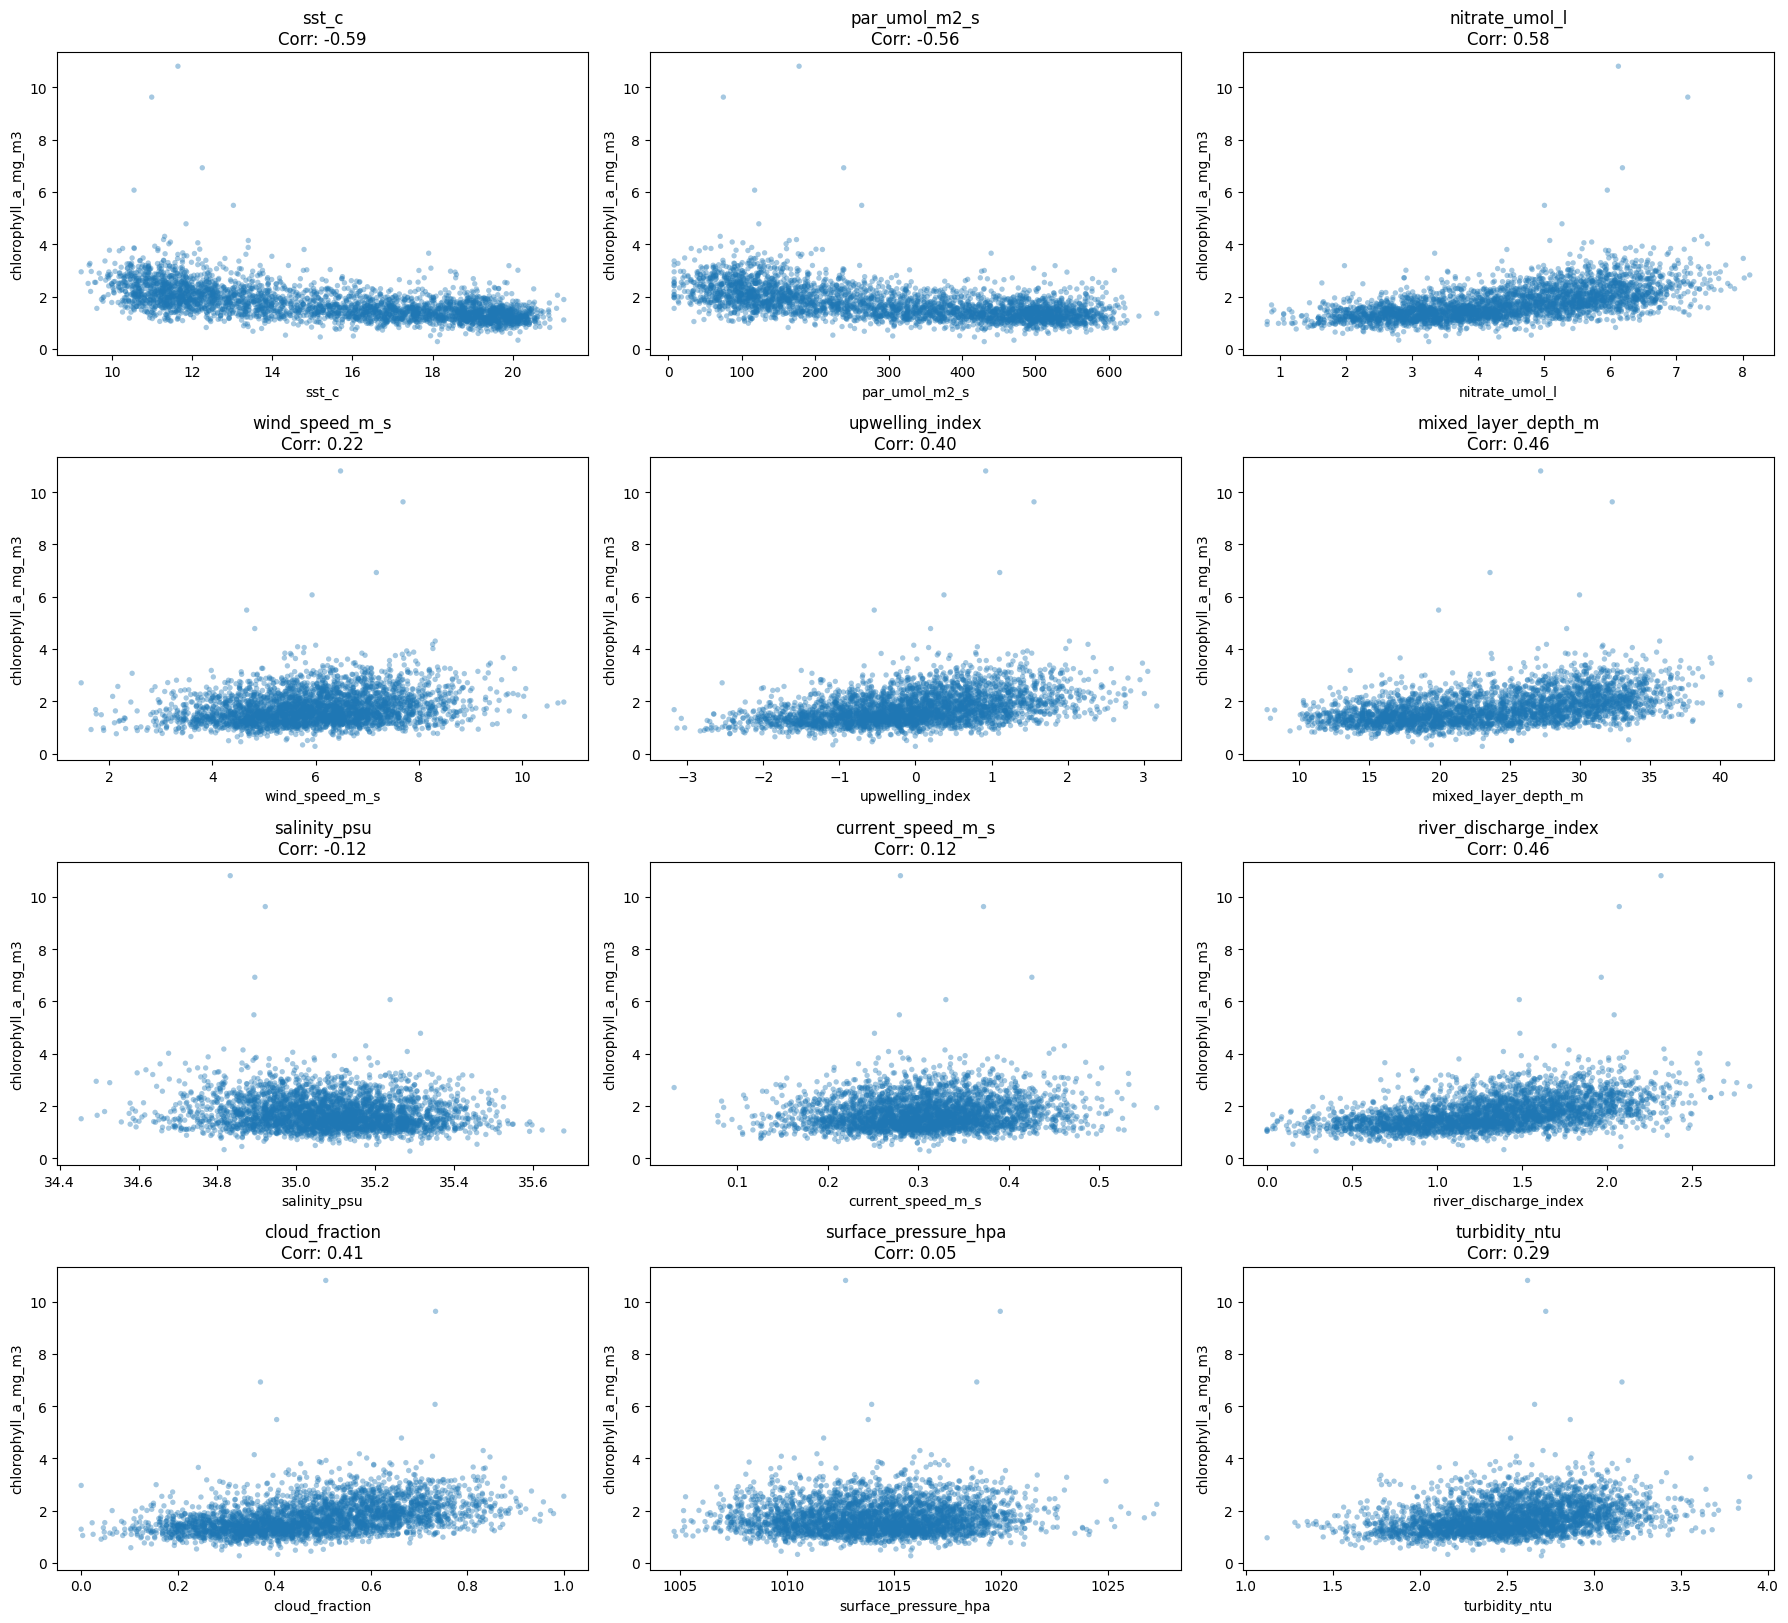

In [4]:
# Load raw data without any transformations
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

target_col = "chlorophyll_a_mg_m3"
exogenous_cols = [col for col in df_raw.columns if col not in ["date", target_col]]

# Plot each exogenous feature (lag 0) against the raw target
plt.figure(figsize=(18, 24))
for i, feature in enumerate(exogenous_cols, 1):
    plt.subplot(6, 3, i)
    plt.scatter(df_raw[feature], df_raw[target_col], alpha=0.4, edgecolors='none', s=15)
    
    # Calculate basic correlation
    corr = df_raw[feature].corr(df_raw[target_col])
    
    plt.title(f"{feature}\nCorr: {corr:.2f}")
    plt.xlabel(feature)
    plt.ylabel(target_col)

plt.tight_layout()
plt.show()

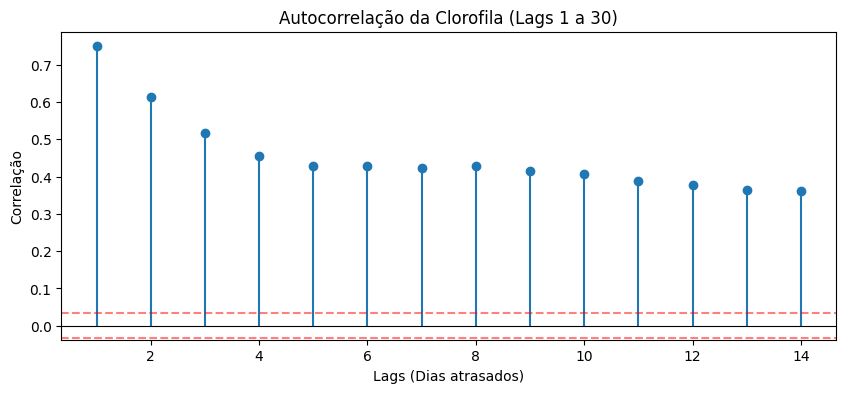

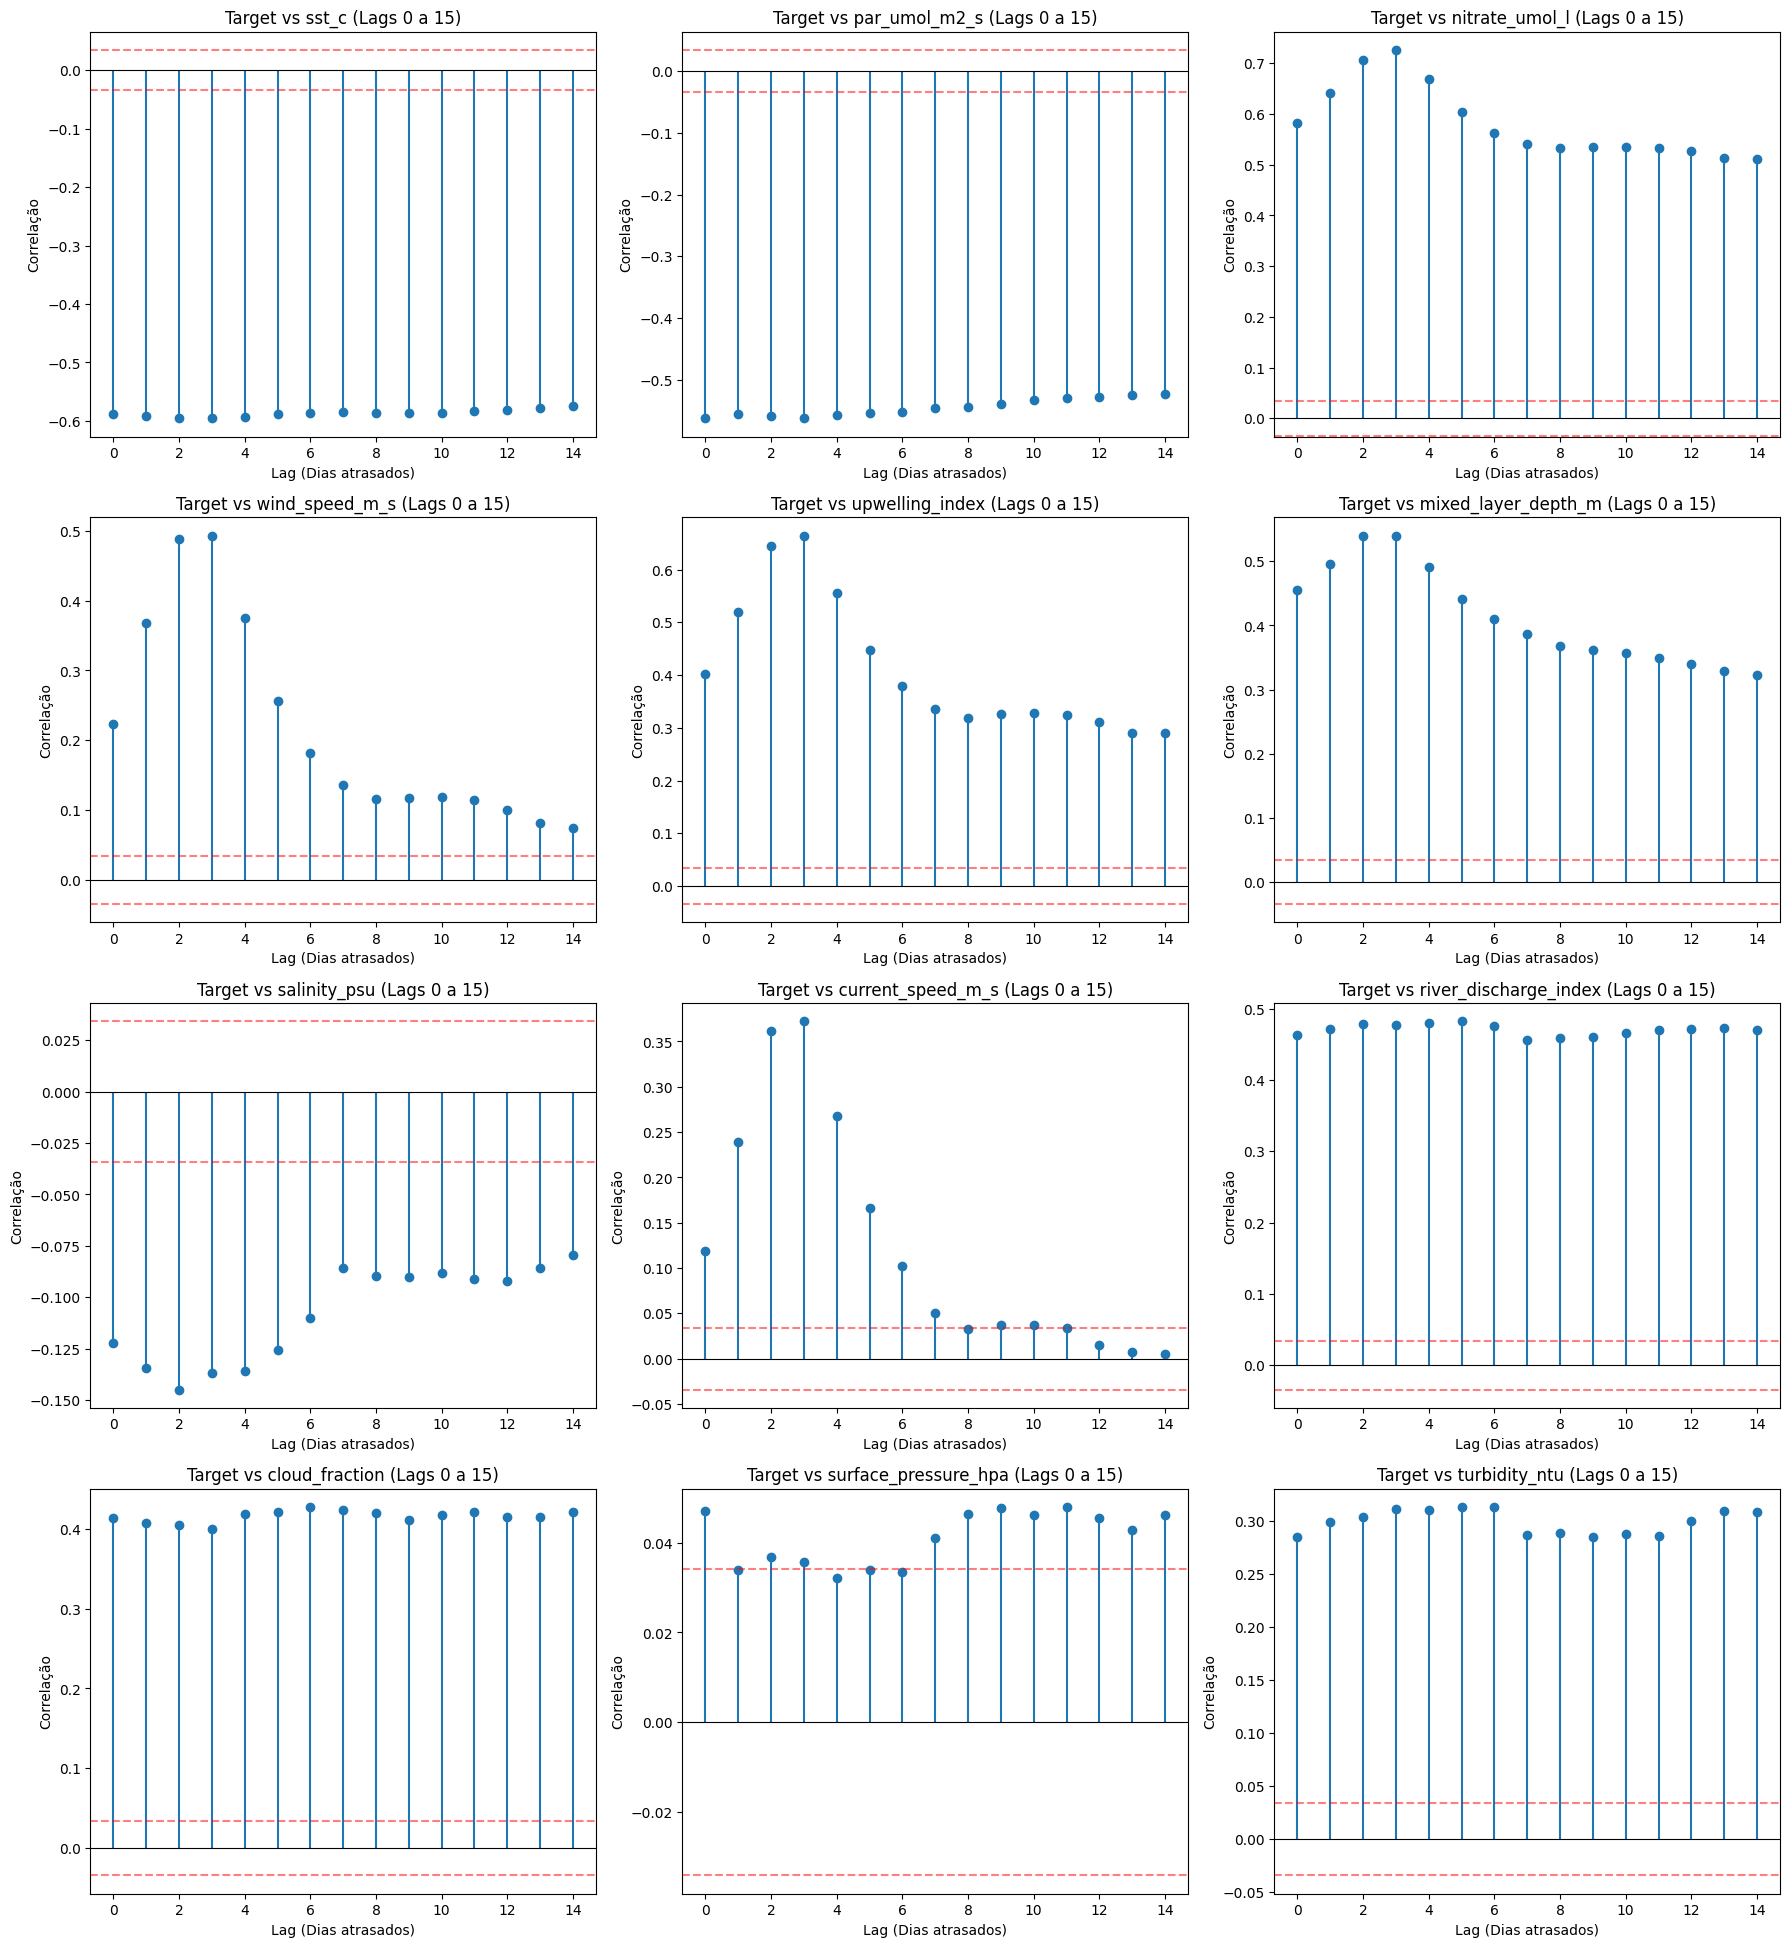

In [11]:
target_col = "chlorophyll_a_mg_m3"
exogenous_cols = [col for col in df_raw.columns if col not in ["date", target_col]]
max_lags = 15

# Autocorrelação da Clorofila
acf_values = [df_raw[target_col].corr(df_raw[target_col].shift(lag)) for lag in range(1, max_lags)]

plt.figure(figsize=(10, 4))
plt.stem(range(1, max_lags), acf_values, basefmt=" ")
plt.axhline(0, color='black', linewidth=0.8)

# Linhas de significância estatística aproximada (95% de confiança)
conf_level = 1.96 / np.sqrt(len(df_raw))
plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
plt.title("Autocorrelação da Clorofila (Lags 1 a 30)")
plt.xlabel("Lags (Dias atrasados)")
plt.ylabel("Correlação")
plt.show()

# Correlação com as variáveis exógenas
plt.figure(figsize=(18, 24))

for i, feature in enumerate(exogenous_cols, 1):
    # Para as variáveis exógenas, o lag 0 é permitido 
    ccf_values = [df_raw[target_col].corr(df_raw[feature].shift(lag)) for lag in range(0, max_lags)]
    
    plt.subplot(5, 3, i)
    plt.stem(range(0, max_lags), ccf_values, basefmt=" ")
    plt.axhline(0, color='black', linewidth=0.8)
    plt.axhline(conf_level, color='red', linestyle='--', alpha=0.5)
    plt.axhline(-conf_level, color='red', linestyle='--', alpha=0.5)
    
    plt.title(f"Target vs {feature} (Lags 0 a 15)")
    plt.xlabel("Lag (Dias atrasados)")
    plt.ylabel("Correlação")

plt.tight_layout()
plt.show()

## 2. Base Preprocessing and Initial Observations

Our baseline approach involves generating historical lag features (1-15 days for the target, 0-15 days for exogenous variables) and encoding the day of the year cyclically. 

In this initial phase, we scale the data but **do not** apply target transformations or outlier smoothing. This establishes a baseline to measure future pipeline improvements against.

In [5]:
from build_lagged_features import build_lagged_frame

DATE = "date"
TARGET = "chlorophyll_a_mg_m3"

defined_lags = {
    TARGET: list(range(1, 15)),
    "sst_c": list(range(0, 15)),
    "par_umol_m2_s": list(range(0, 15)),
    "nitrate_umol_l": list(range(0, 15)),
    "wind_speed_m_s": list(range(0, 15)),
    "upwelling_index": list(range(0, 15)),
    "mixed_layer_depth_m": list(range(0, 15)),
    "salinity_psu": list(range(0, 15)),
    "current_speed_m_s": list(range(0, 15)),
    "river_discharge_index": list(range(0, 15)),
    "cloud_fraction": list(range(0, 15)),
    "surface_pressure_hpa": list(range(0, 15)),
    "turbidity_ntu": list(range(0, 15)),
}

# Build baseline features using the imported function
df_baseline = build_lagged_frame(df_raw, lag_spec=defined_lags)

# Chronological split (Train, Validation, Test)
lower_sep = -2*365
higher_sep = -365

X_base = df_baseline.drop(columns=[DATE, TARGET])
Y_base = df_baseline[TARGET]

X_train_base = X_base.iloc[:lower_sep]
X_val_base = X_base.iloc[lower_sep:higher_sep]
X_test_base = X_base.iloc[higher_sep:]

Y_train_base = Y_base.iloc[:lower_sep]
Y_val_base = Y_base.iloc[lower_sep:higher_sep]
Y_test_base = Y_base.iloc[higher_sep:]

# Baseline Scaling
scaler_base = StandardScaler()
X_train_scaled_base = pd.DataFrame(scaler_base.fit_transform(X_train_base), columns=X_train_base.columns)
X_val_scaled_base = pd.DataFrame(scaler_base.transform(X_val_base), columns=X_val_base.columns)
X_test_scaled_base = pd.DataFrame(scaler_base.transform(X_test_base), columns=X_test_base.columns)

# Baseline Lasso Fit
baseline_lasso = linear_model.Lasso(alpha=0.01, max_iter=10000)
baseline_lasso.fit(X_train_scaled_base, Y_train_base)

baseline_val_preds = baseline_lasso.predict(X_val_scaled_base)
baseline_test_preds = baseline_lasso.predict(X_test_scaled_base)

print(f"Baseline Validation R^2: {r2_score(Y_val_base, baseline_val_preds):.4f}")
print(f"Baseline Validation MAE: {mean_absolute_error(Y_val_base, baseline_val_preds):.4f}")
print(f"Baseline Test R^2: {r2_score(Y_test_base, baseline_test_preds):.4f}")
print(f"Baseline Test MAE: {mean_absolute_error(Y_test_base, baseline_test_preds):.4f}")

Baseline Validation R^2: 0.8344
Baseline Validation MAE: 0.1707
Baseline Test R^2: 0.5116
Baseline Test MAE: 0.2188


### 2.1 The Danger of Data Leakage: 2-Way vs. 3-Way Splits

A common pitfall in machine learning is using a simple 2-way split (Train/Test) and tuning hyperparameters directly on the test set. This leaks information about the unseen future data into the model configuration, resulting in an artificially inflated performance metric that will not hold up when testing with new data.

Furthermore, tuning on the Test set causes the model to select a different underlying architecture (in Lasso's case, the number of retained features). It will adjust its sparsity to artificially "fit" the noise in the Test set, completely changing which environmental variables are deemed important.

To demonstrate this, we will compare two approaches while keeping the training data strictly identical:
1. **Flawed 2-Way Split:** We train on the Train set, but pick the best `alpha` by checking which one scores highest directly on the Test set.
2. **Proper 3-Way Split:** We train on the Train set, pick the best `alpha` using the Validation set, and then test *only once* on the Test set to get an honest metric.

In [6]:
alphas_to_test = [1.0, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001]

print("--- Flawed 2-Way Split (Tuning on Test Set) ---")
best_test_r2_flawed = -float('inf')
best_alpha_flawed = None
flawed_features_kept = 0

for alpha in alphas_to_test:
    flawed_model = linear_model.Lasso(alpha=alpha, max_iter=10000)
    flawed_model.fit(X_train_scaled_base, Y_train_base)
    
    # DATA LEAKAGE: Peeking at the Test set during the tuning loop!
    test_preds_flawed = flawed_model.predict(X_test_scaled_base)
    test_r2_flawed = r2_score(Y_test_base, test_preds_flawed)
    
    if test_r2_flawed > best_test_r2_flawed:
        best_test_r2_flawed = test_r2_flawed
        best_alpha_flawed = alpha
        flawed_features_kept = np.sum(flawed_model.coef_ != 0)

print(f"Chosen Alpha: {best_alpha_flawed}")
print(f"Features Kept by Model: {flawed_features_kept} ")
print(f"Reported Test R^2: {best_test_r2_flawed:.4f} \n")


print("--- Proper 3-Way Split (Tuning on Validation Set) ---")
best_val_r2_proper = -float('inf')
best_alpha_proper = None

# Step 1 & 2: Train and Tune using strictly Train/Val splits
for alpha in alphas_to_test:
    proper_model = linear_model.Lasso(alpha=alpha, max_iter=10000)
    proper_model.fit(X_train_scaled_base, Y_train_base)
    
    # NO LEAKAGE: Using the Validation set to make decisions
    val_preds_proper = proper_model.predict(X_val_scaled_base)
    val_r2_proper = r2_score(Y_val_base, val_preds_proper)
    
    if val_r2_proper > best_val_r2_proper:
        best_val_r2_proper = val_r2_proper
        best_alpha_proper = alpha

# Step 3: Test exactly once using the chosen alpha
final_proper_model = linear_model.Lasso(alpha=best_alpha_proper, max_iter=10000)
final_proper_model.fit(X_train_scaled_base, Y_train_base)
proper_test_preds = final_proper_model.predict(X_test_scaled_base)
proper_test_r2 = r2_score(Y_test_base, proper_test_preds)
proper_features_kept = np.sum(final_proper_model.coef_ != 0)

print(f"Chosen Alpha: {best_alpha_proper}")
print(f"Features Kept by Model: {proper_features_kept} ")
print(f"True Unbiased Test R^2: {proper_test_r2:.4f}")
print(f"\nGap in reported performance: {(best_test_r2_flawed - proper_test_r2):.4f}")

--- Flawed 2-Way Split (Tuning on Test Set) ---
Chosen Alpha: 0.005
Features Kept by Model: 38 
Reported Test R^2: 0.5132 

--- Proper 3-Way Split (Tuning on Validation Set) ---
Chosen Alpha: 0.01
Features Kept by Model: 27 
True Unbiased Test R^2: 0.5116

Gap in reported performance: 0.0017


This results show that, in order to obtain better results in the test split, the 2-Way-Split chose `alpha` = 0.005. This will lead to an overfit of the test data, and adopting a policy of maximizing R^2 based in this should not be done. With the 3-Way-Split, since there is a middle set for validation, with respect to who the optimization of the hyperparameters is done, the test data is only use for a real evaluation. This approach is closer to the evaluation procedure that we will face.

## 3. Preprocessing Study
When analysing the given data, we saw that all of them contain outliers, from `chlorophyll_a_mg_m3` to the exogenous variables. The laboratory guide mentions that some sensors are subjected to noise and some measurements do not reflect the reality. In order to see the scale of this outliers, the various variables were plotted as a function of time



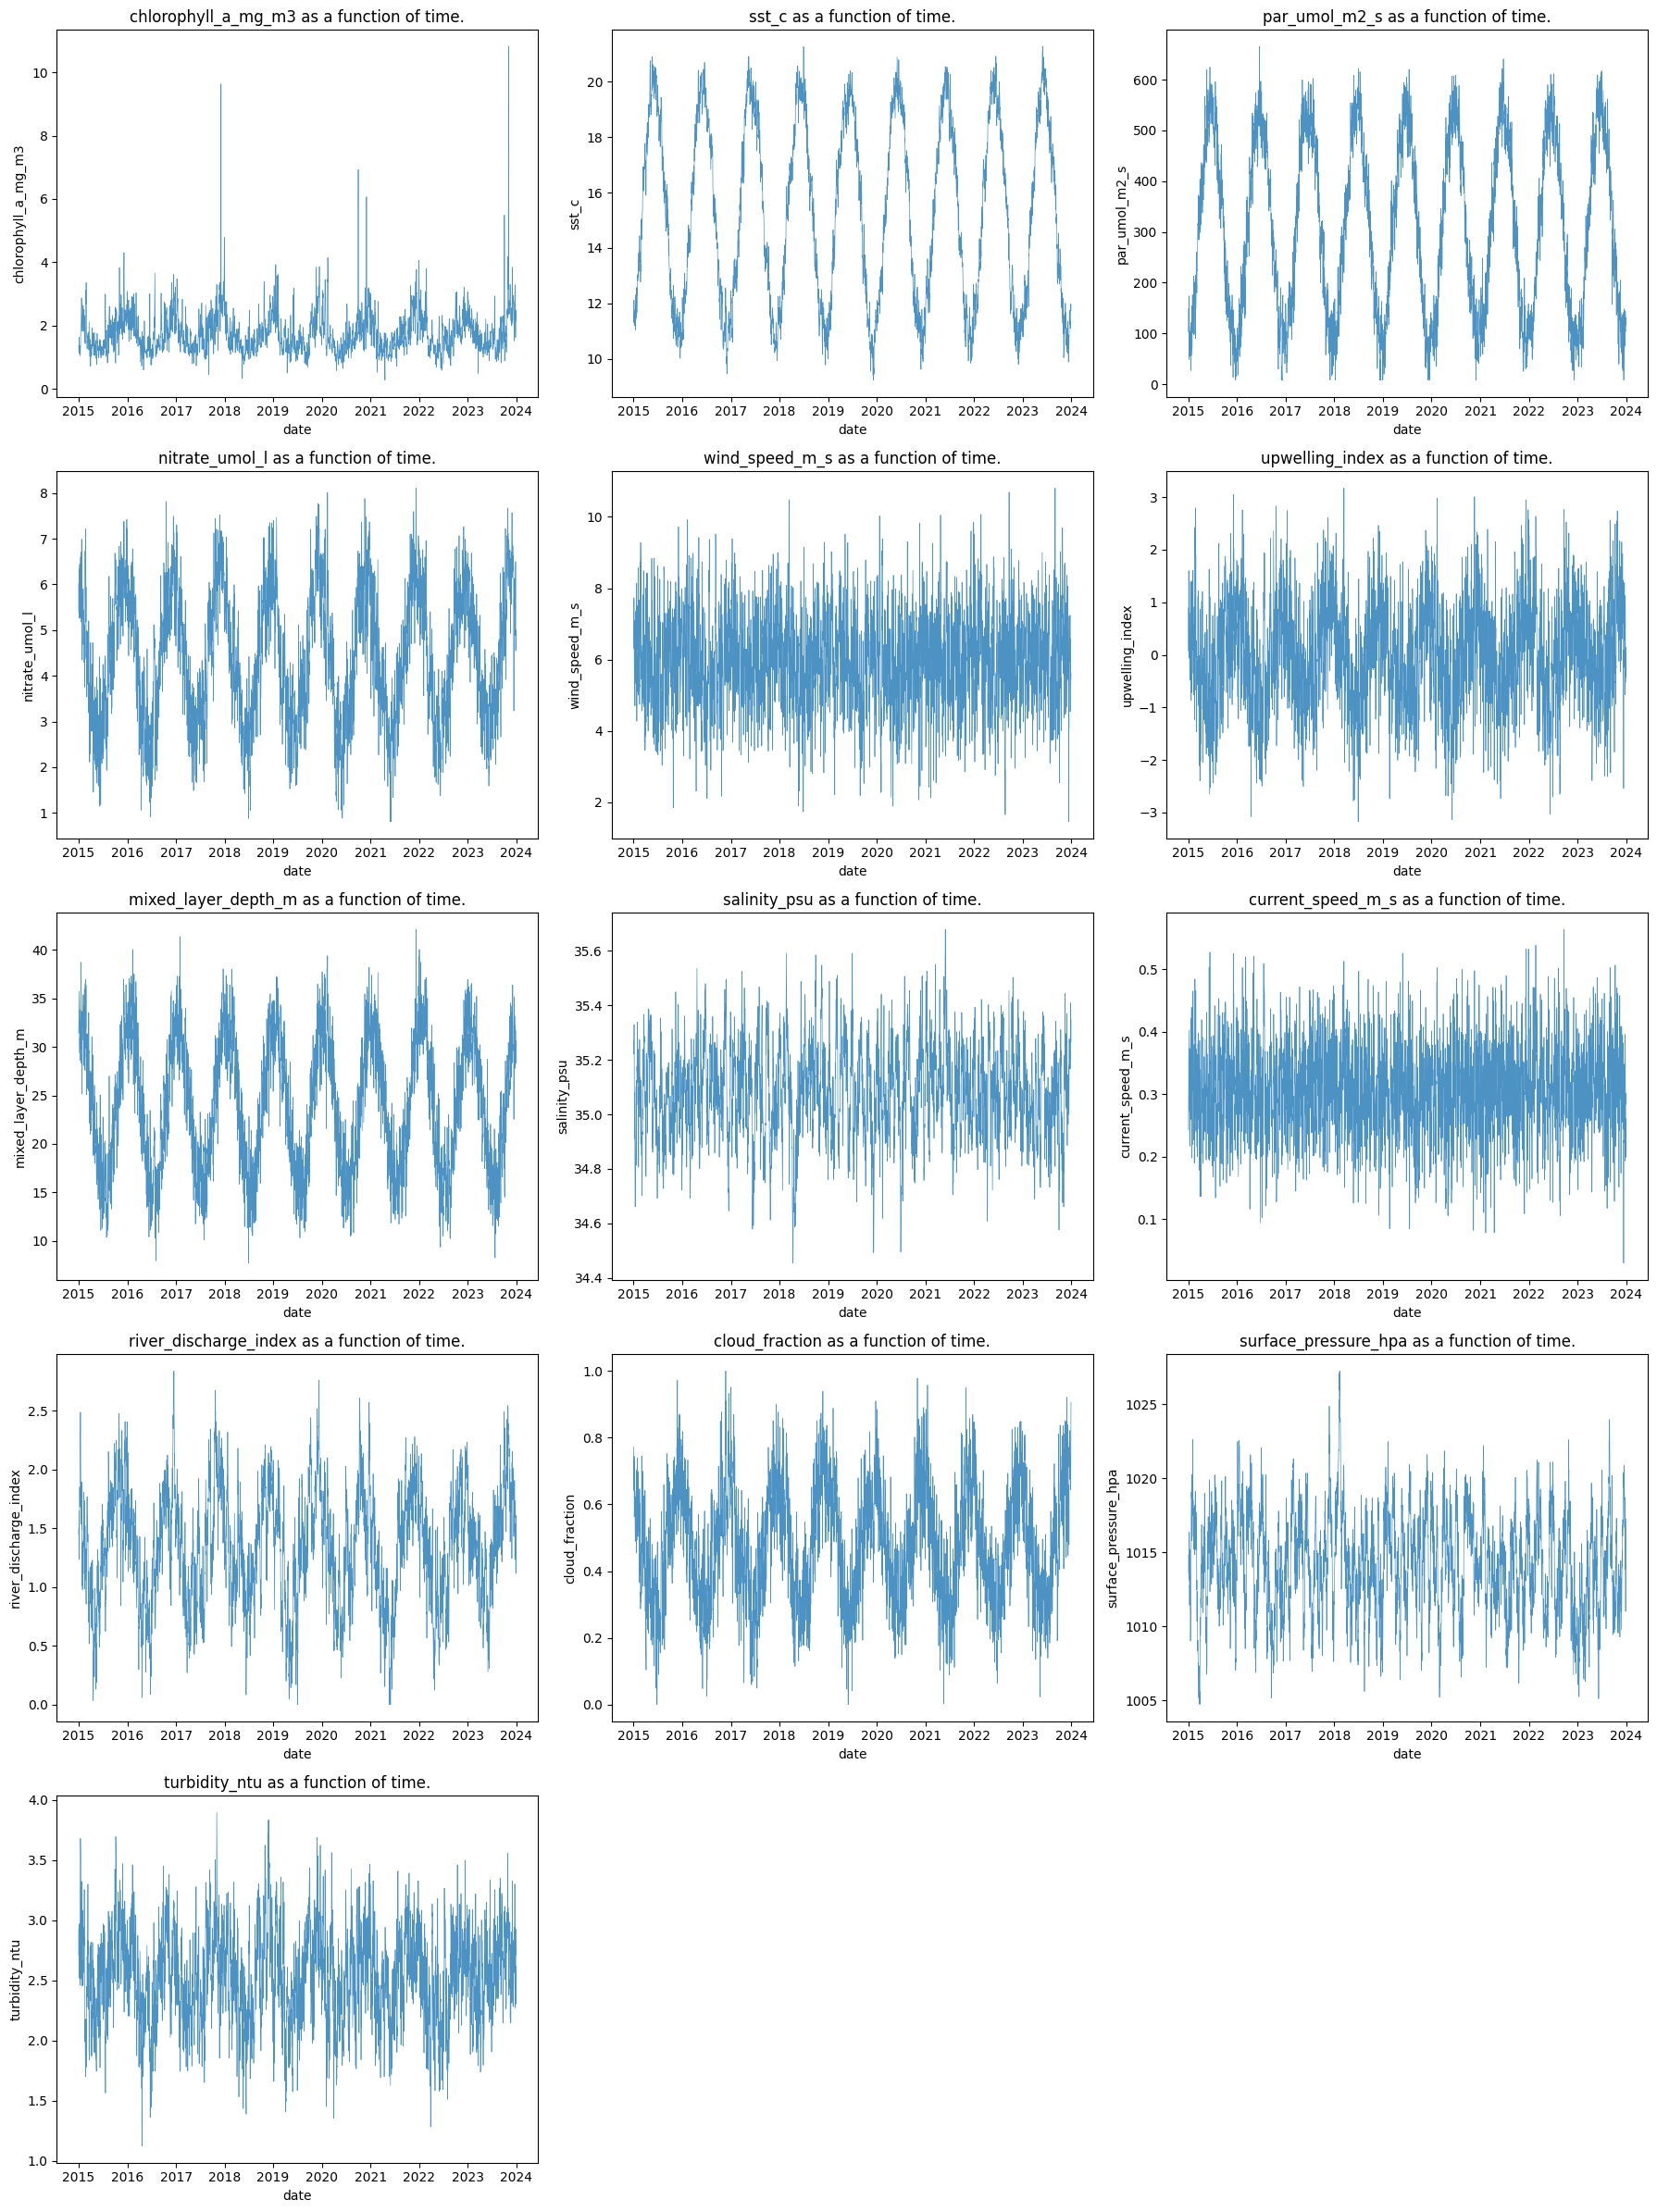

In [9]:
# Load raw data without any transformations
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

time_col = "date"
exogenous_cols = [col for col in df_raw.columns if col not in ["date"]]


plt.figure(figsize=(18, 24))
for i, feature in enumerate(exogenous_cols, 1):
    plt.subplot(5, 3, i)
    plt.plot(df_raw[time_col],df_raw[feature], alpha=0.8, linewidth=0.5)
    
    plt.title(f"{feature} as a function of time.")
    plt.xlabel(time_col)
    plt.ylabel(feature)

plt.tight_layout()
plt.show()


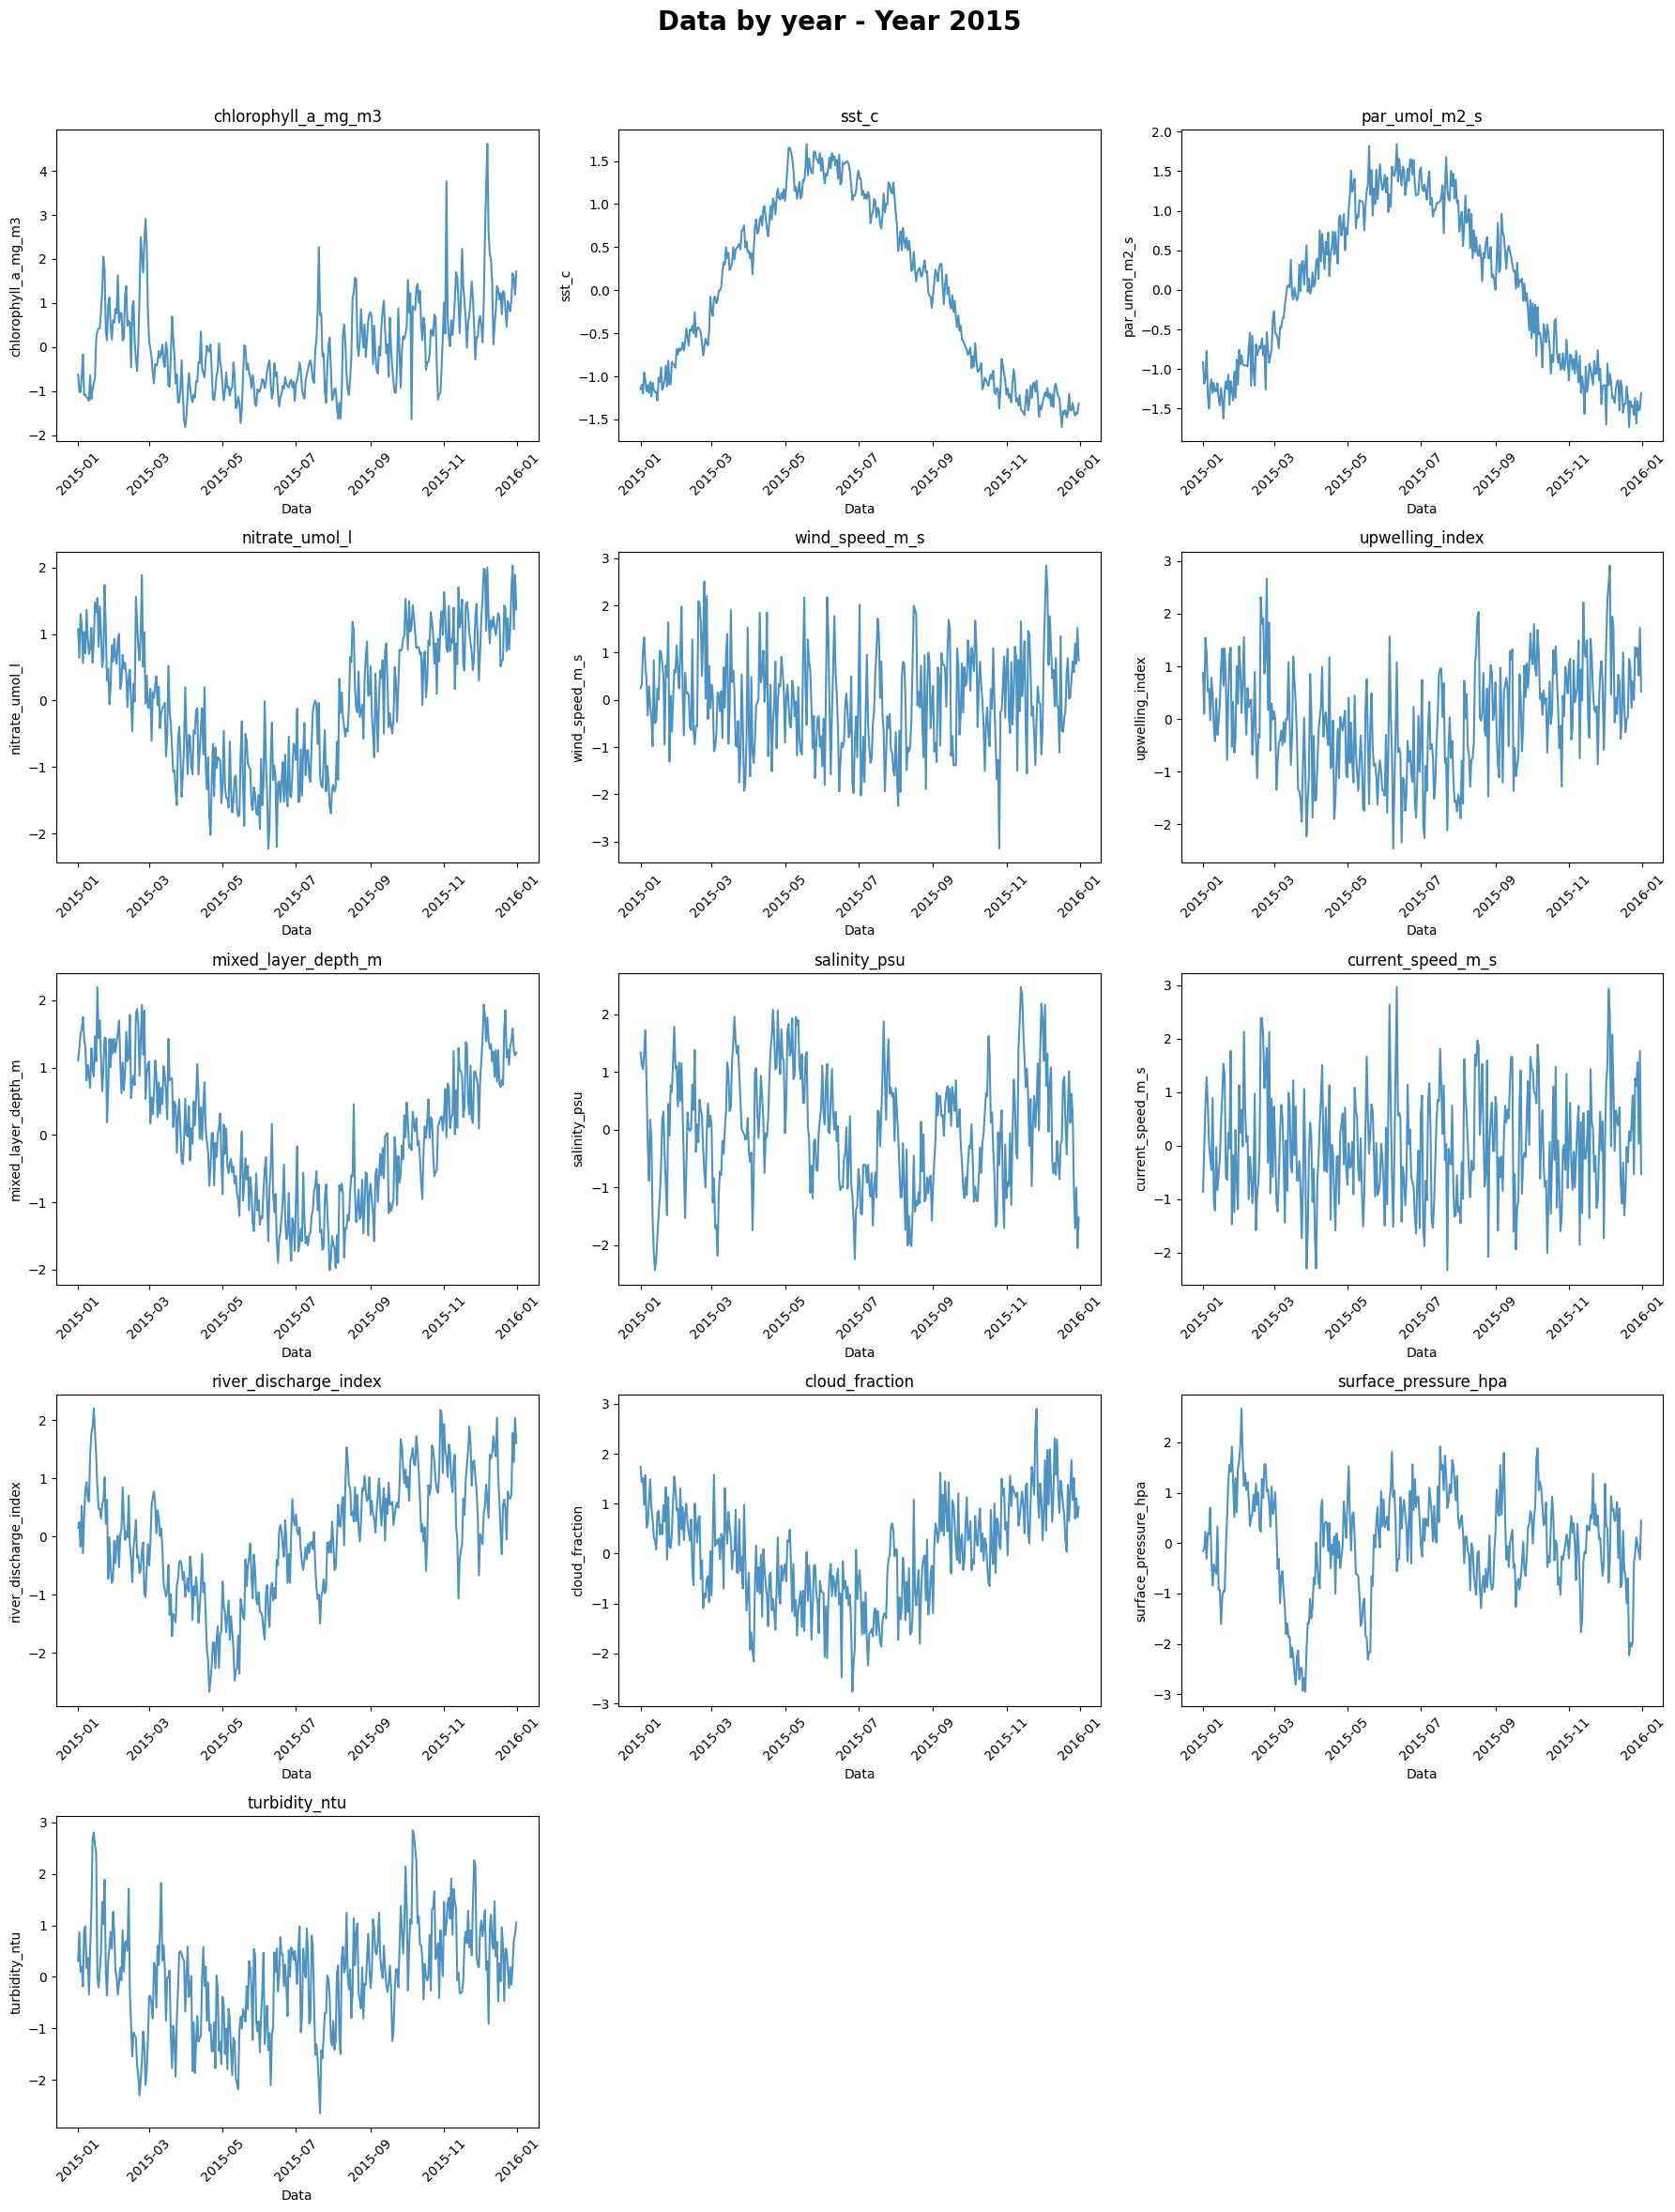

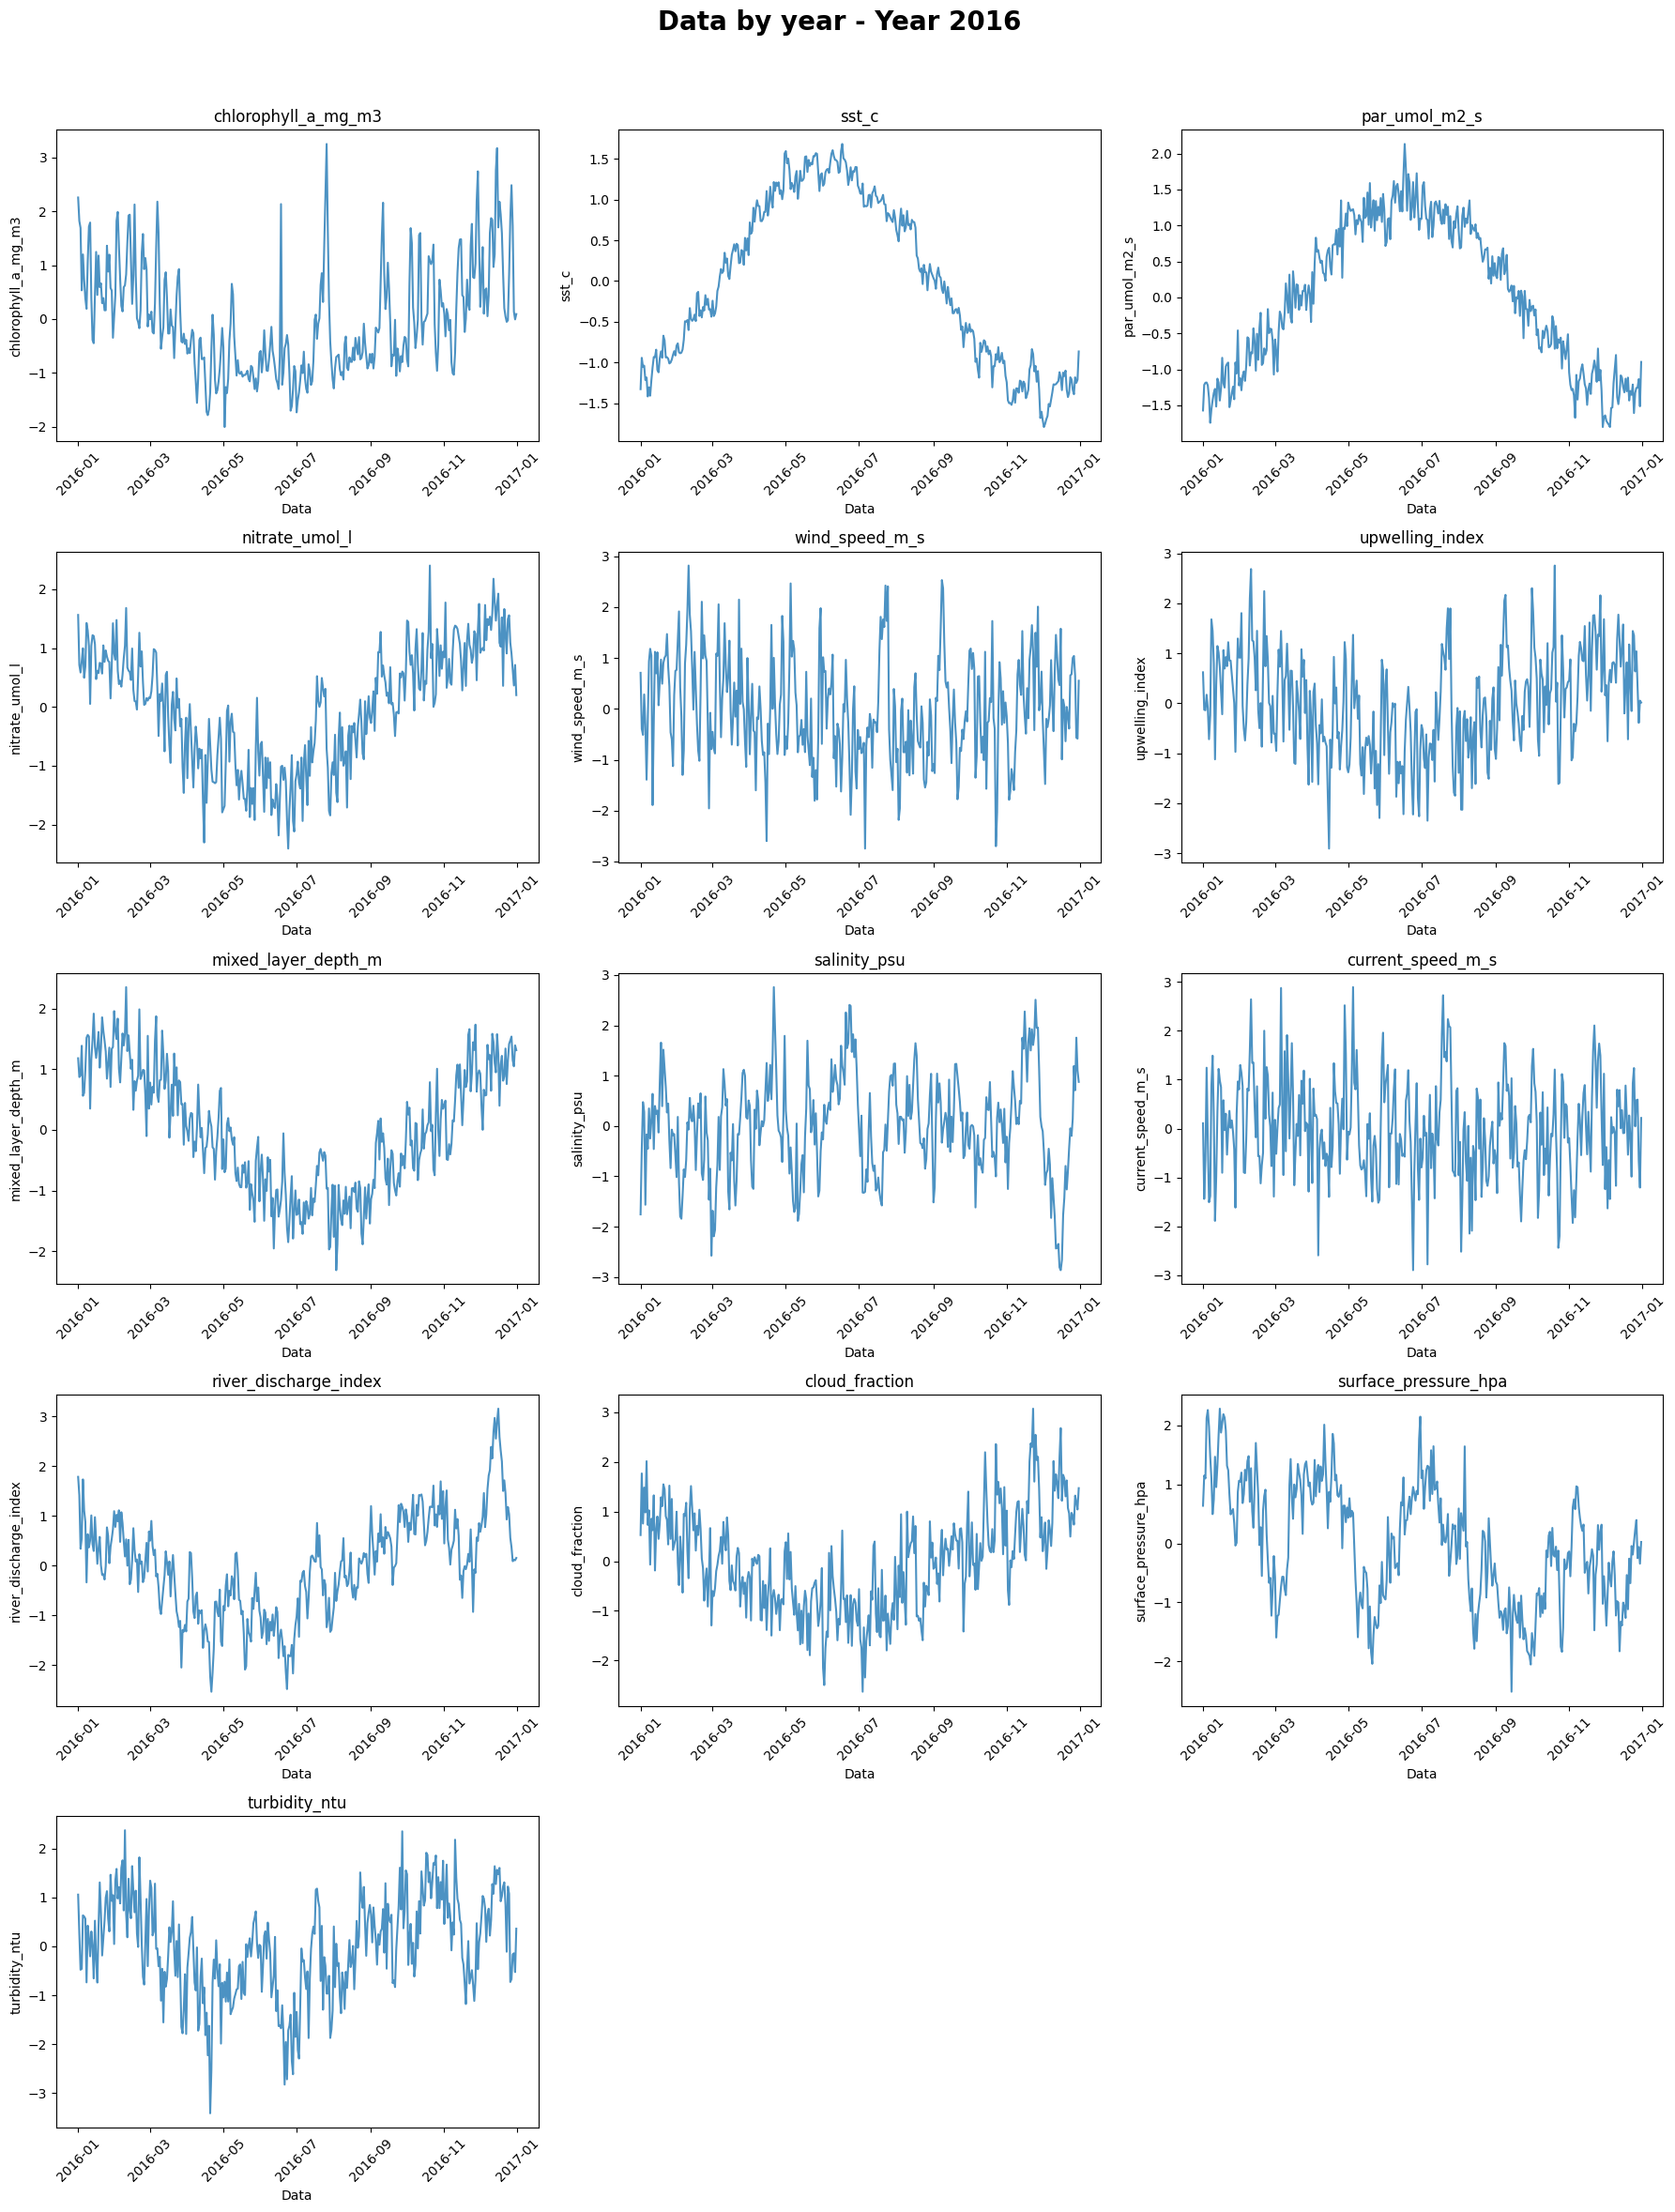

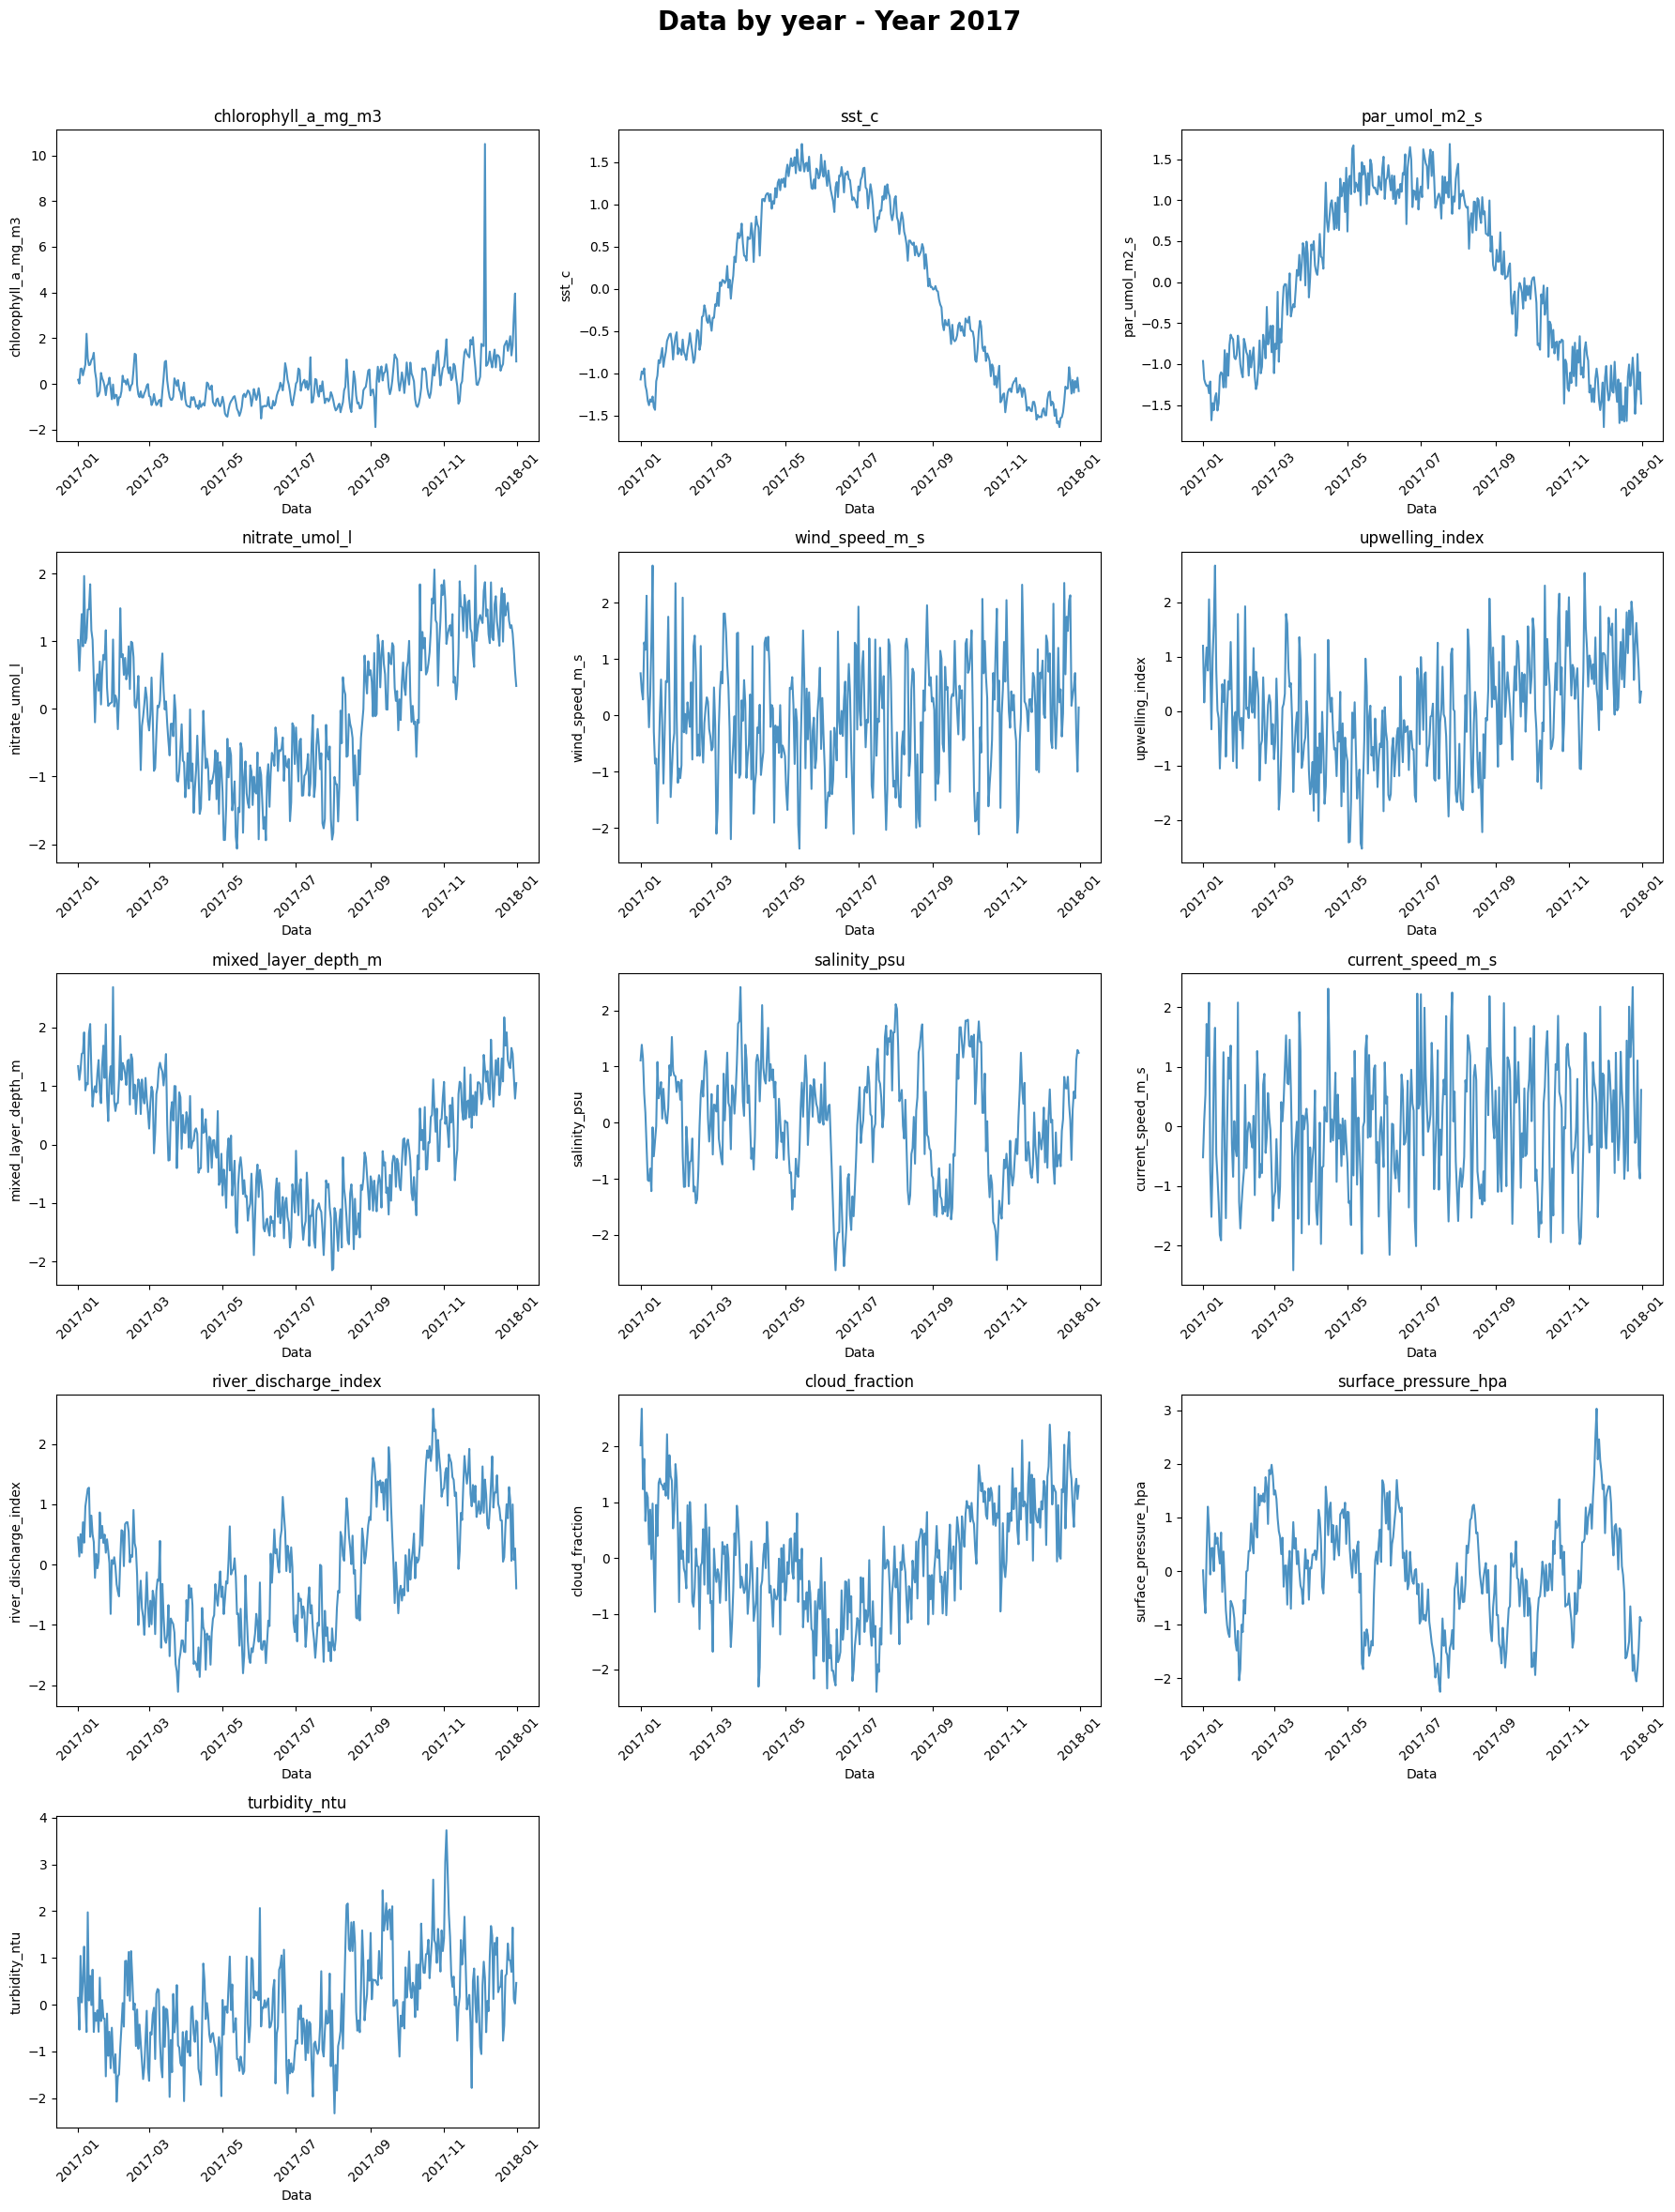

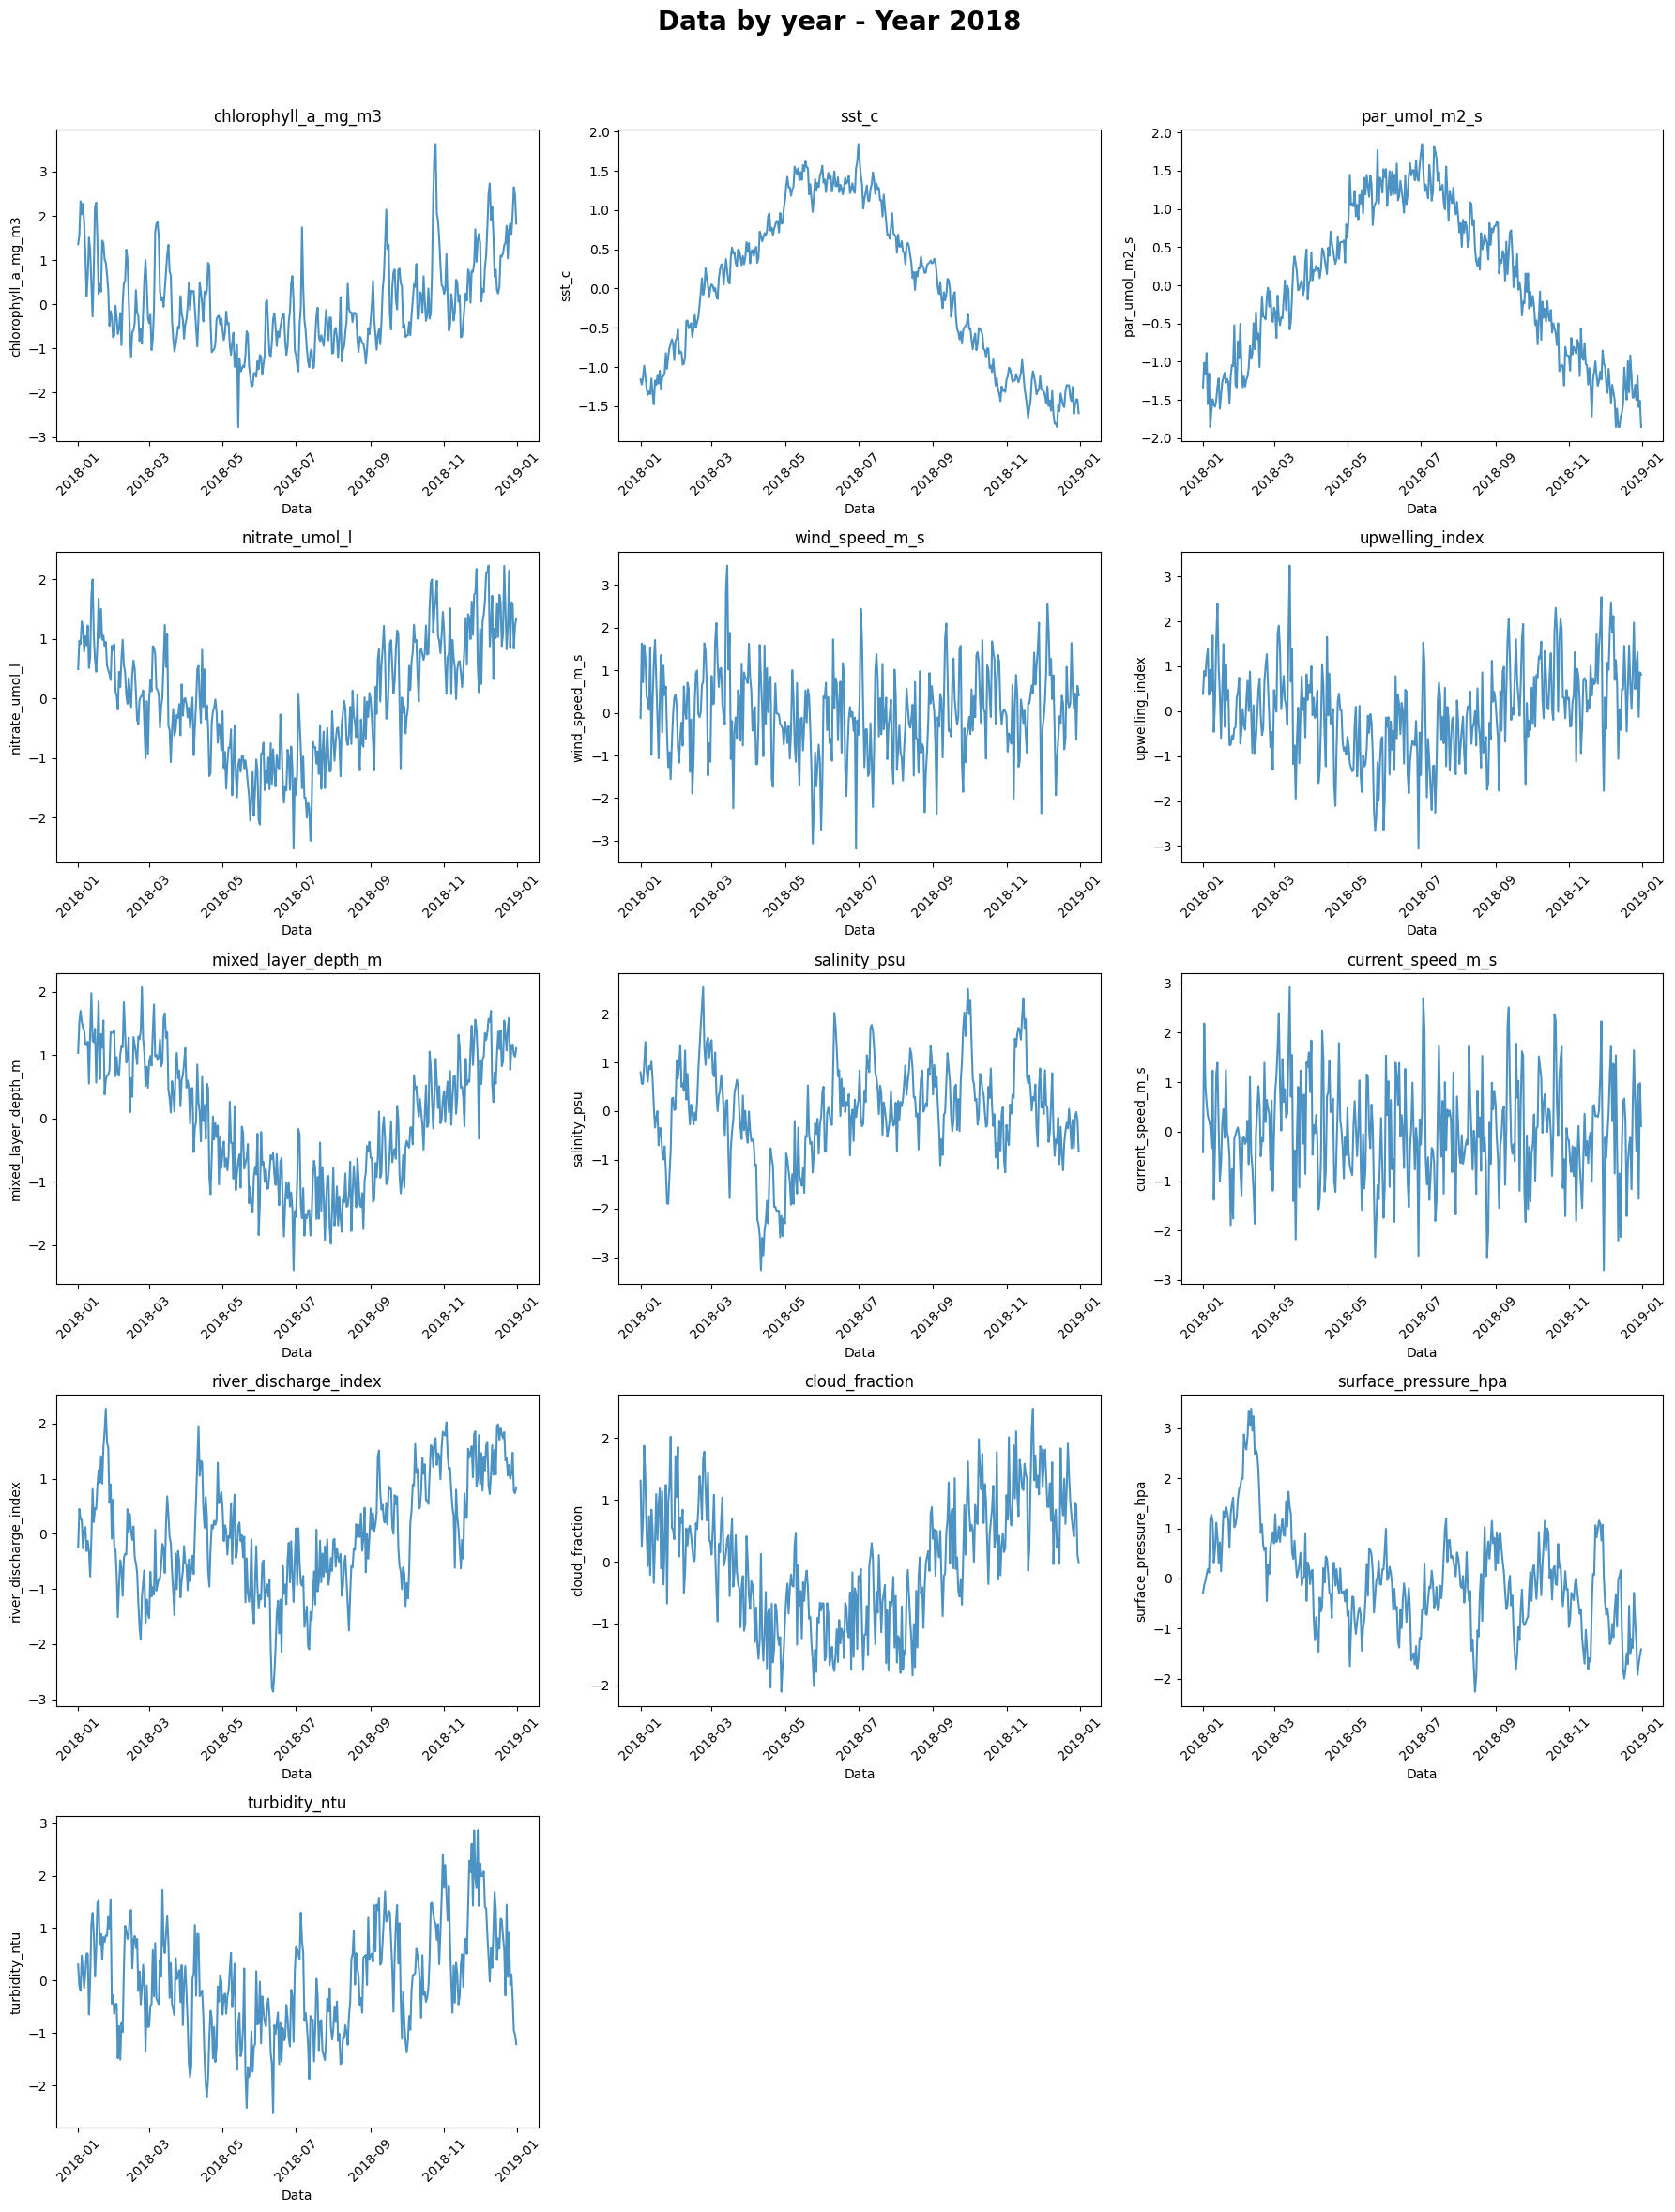

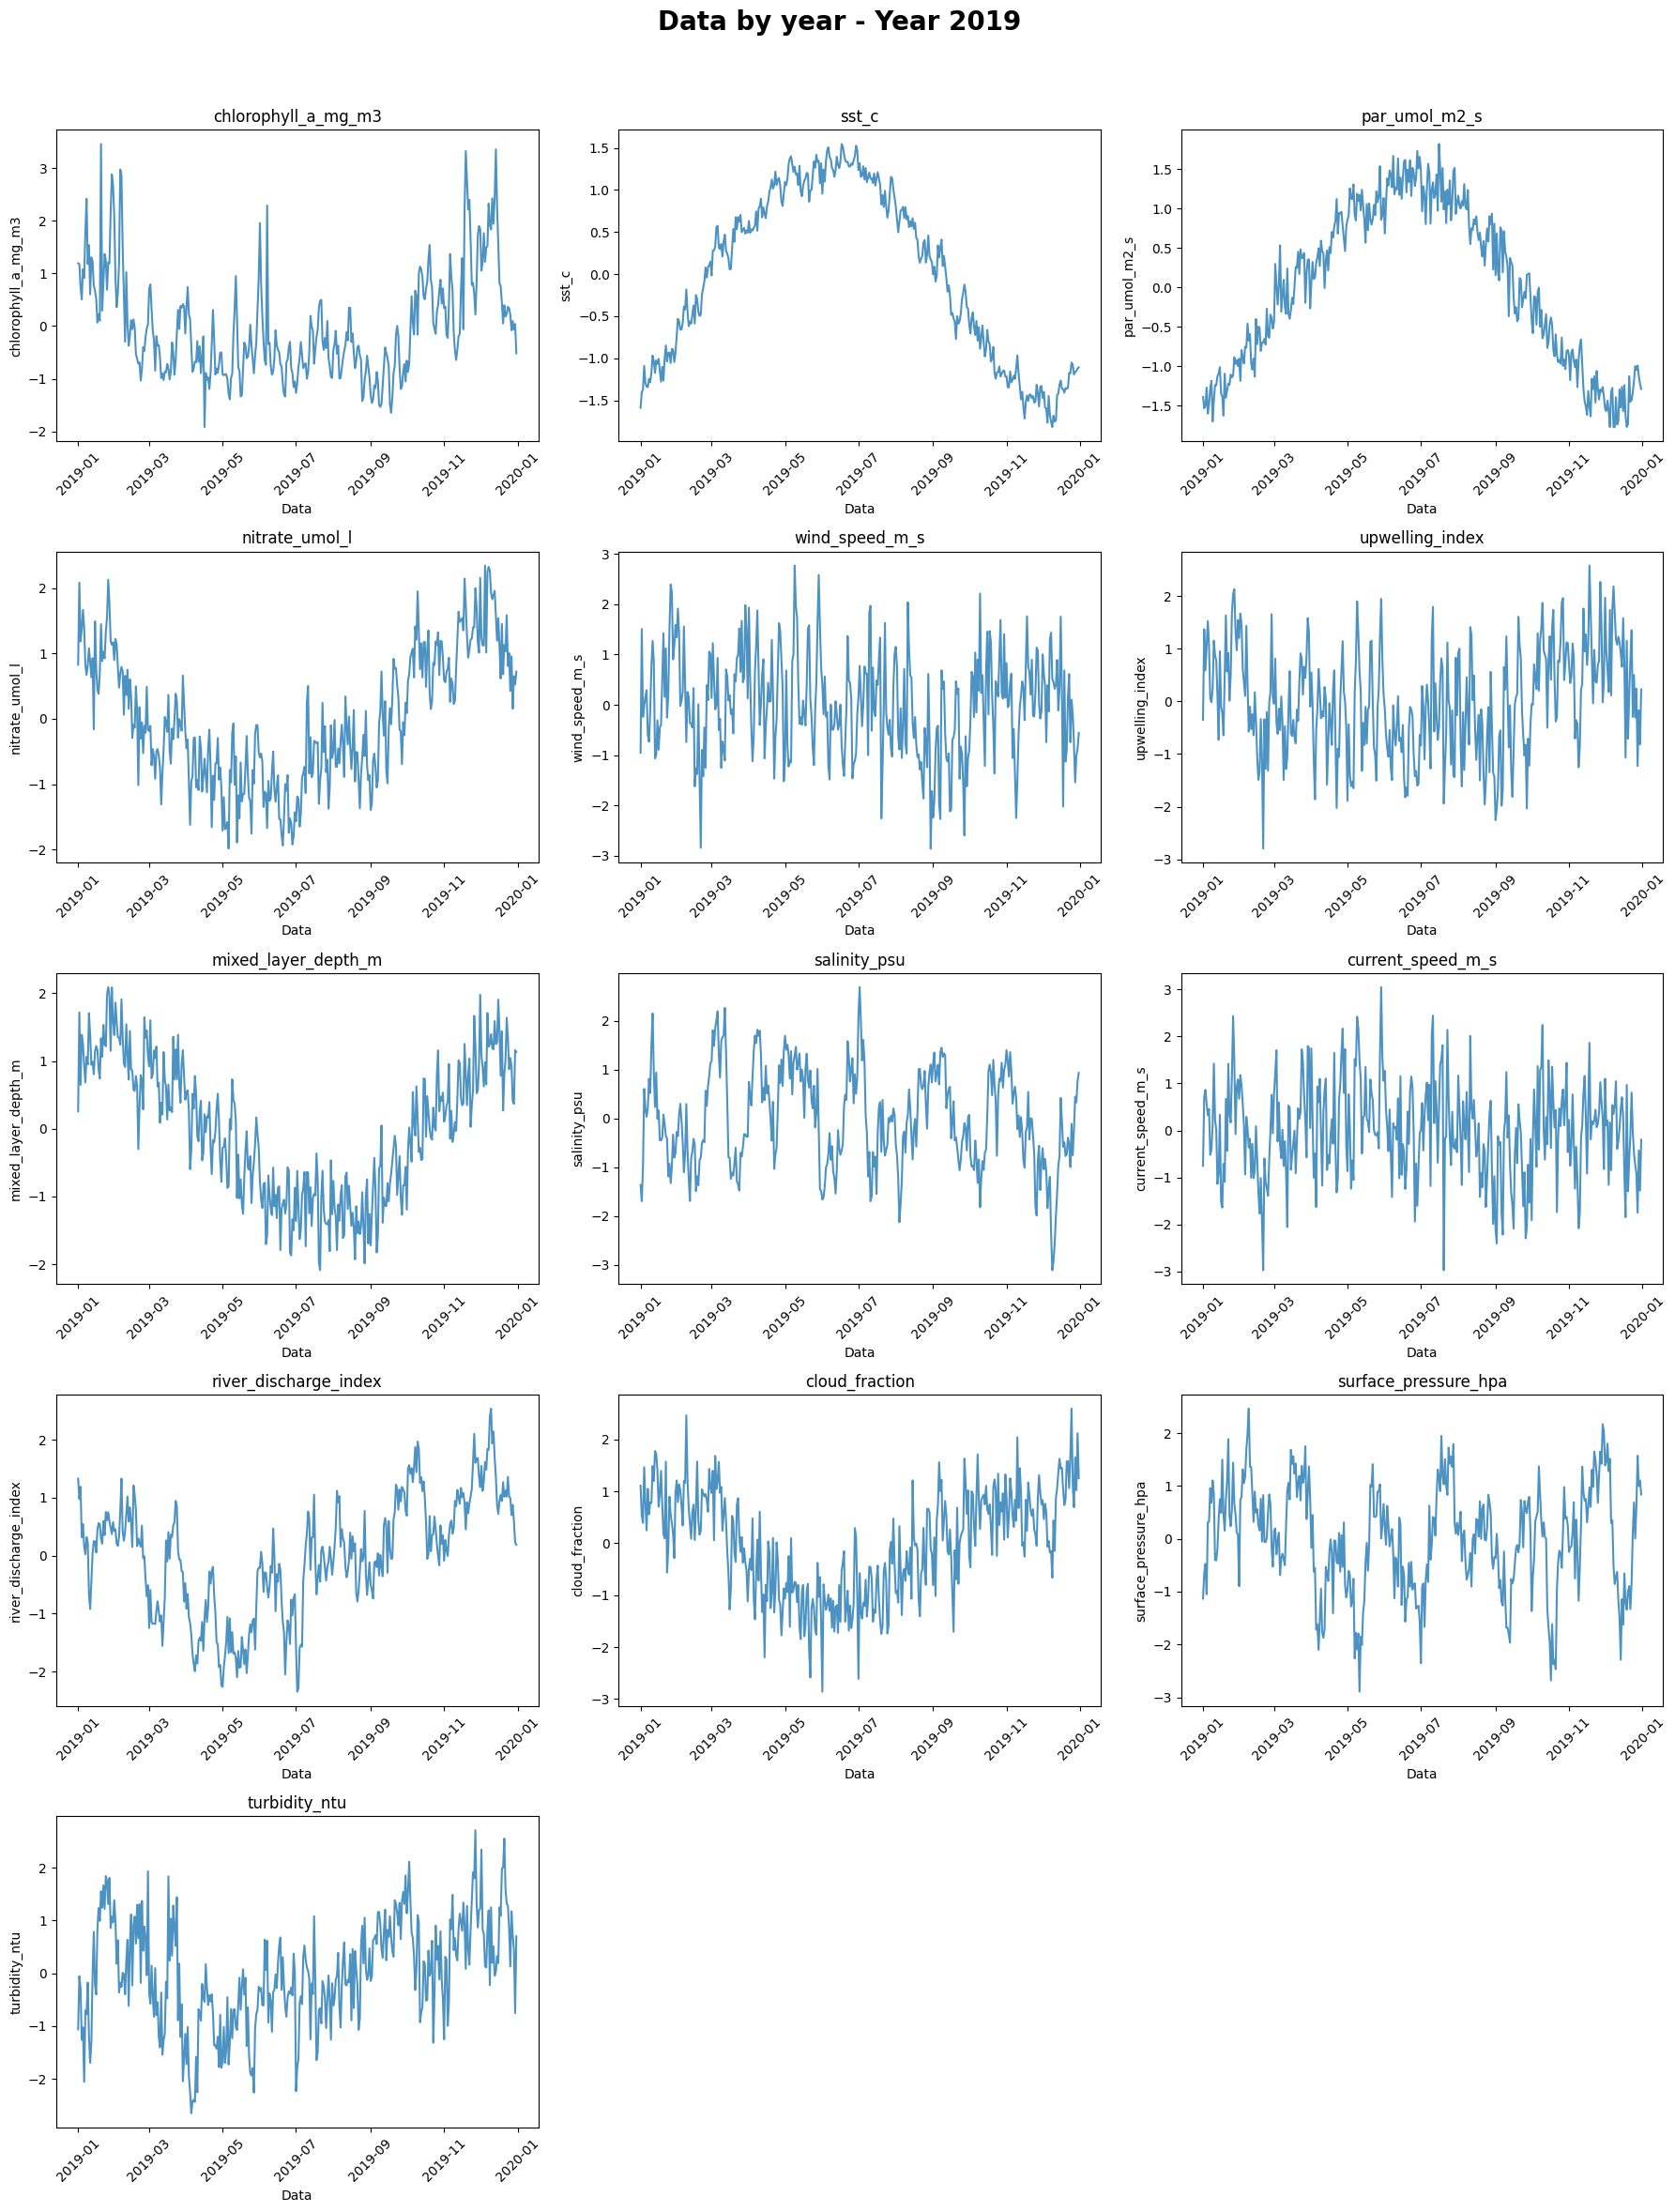

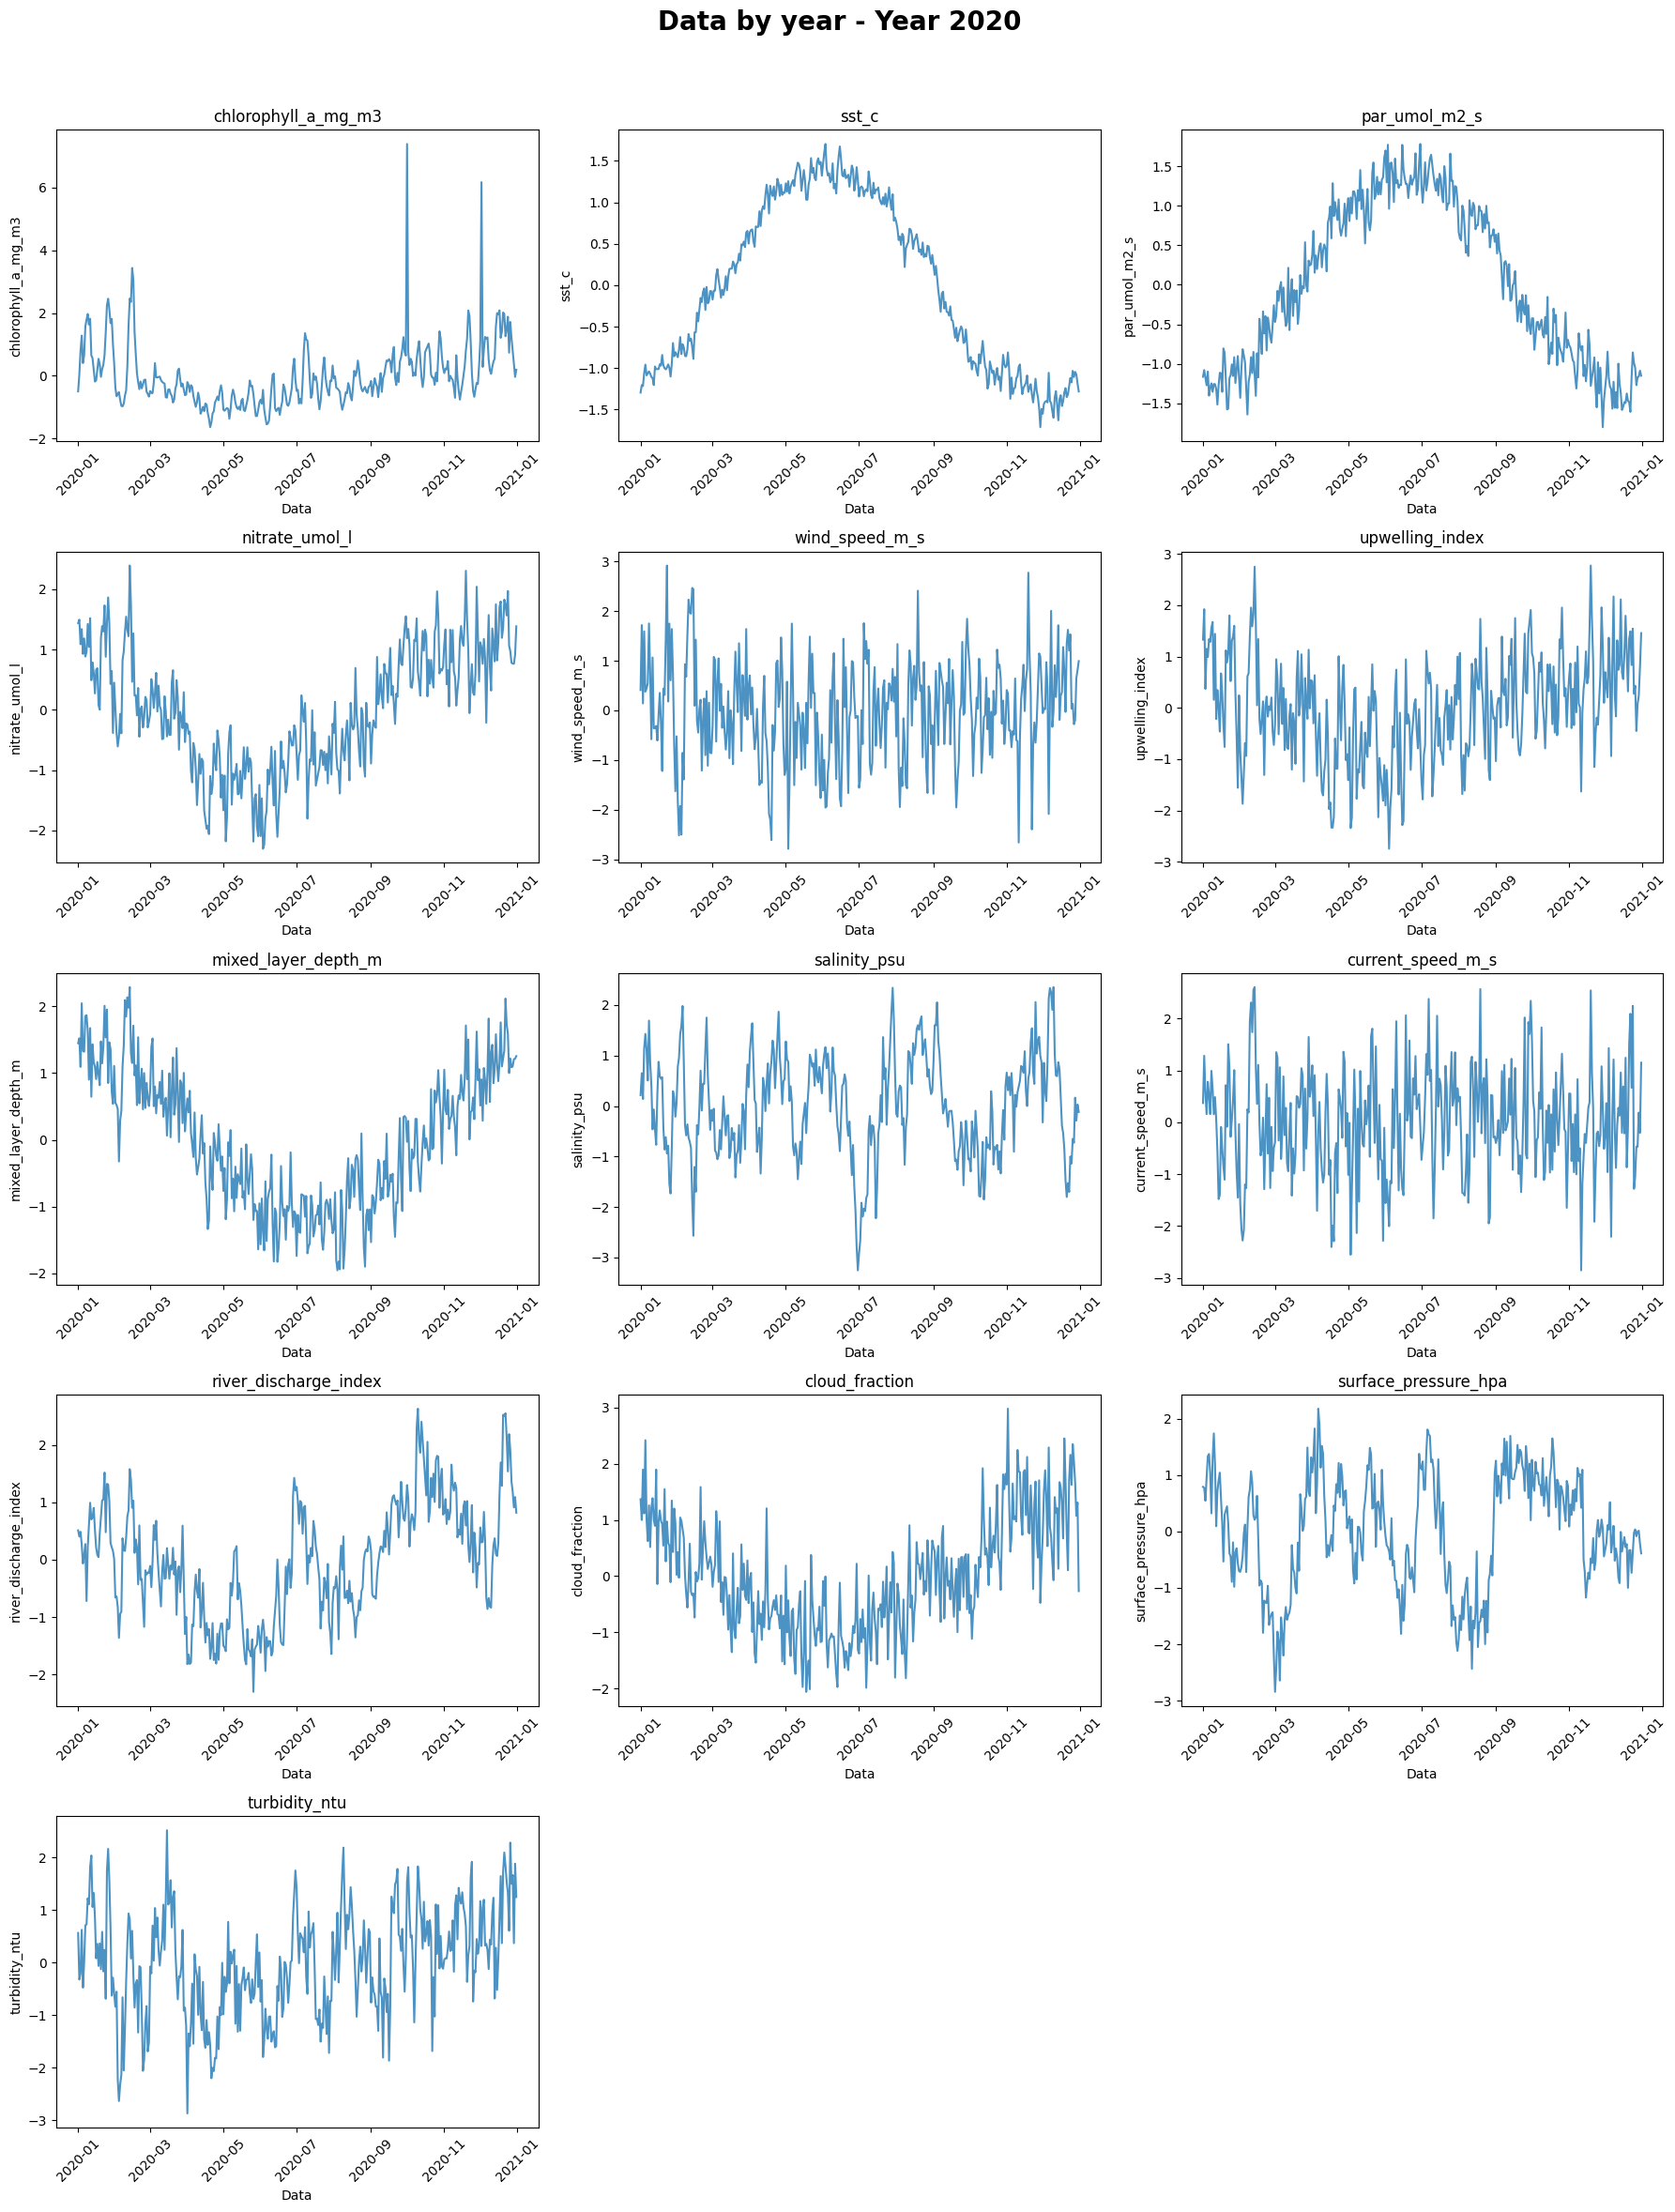

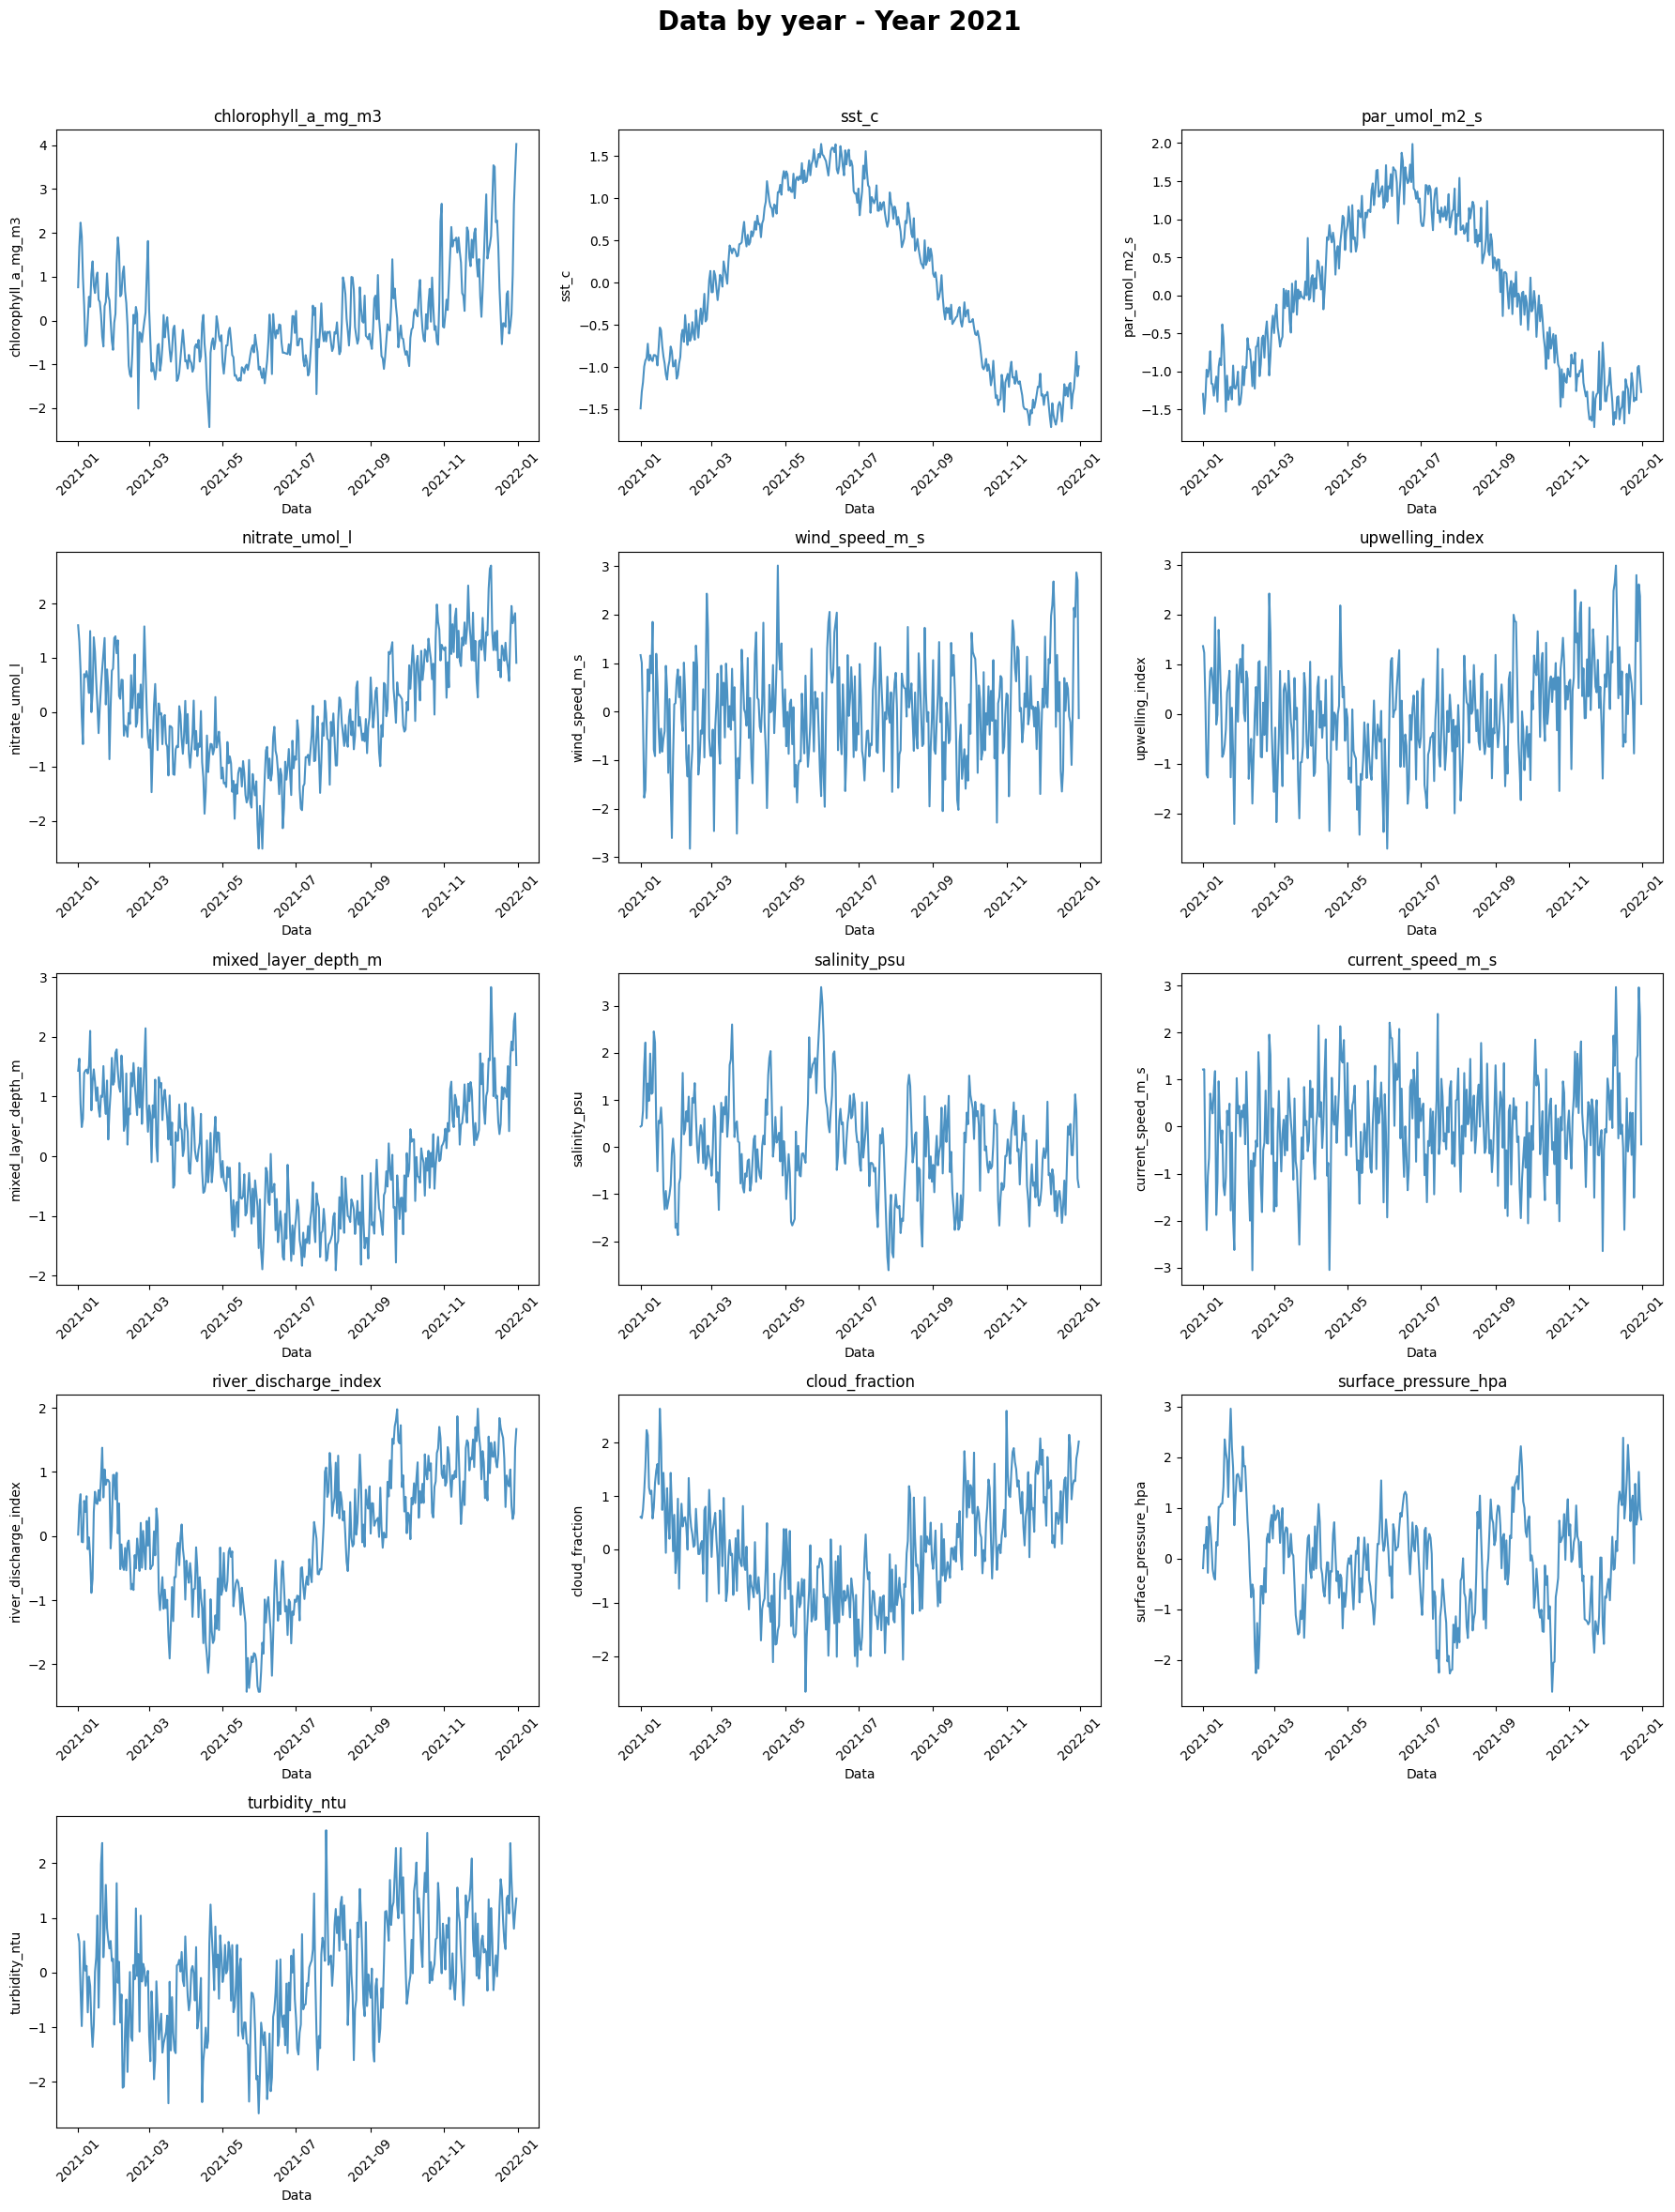

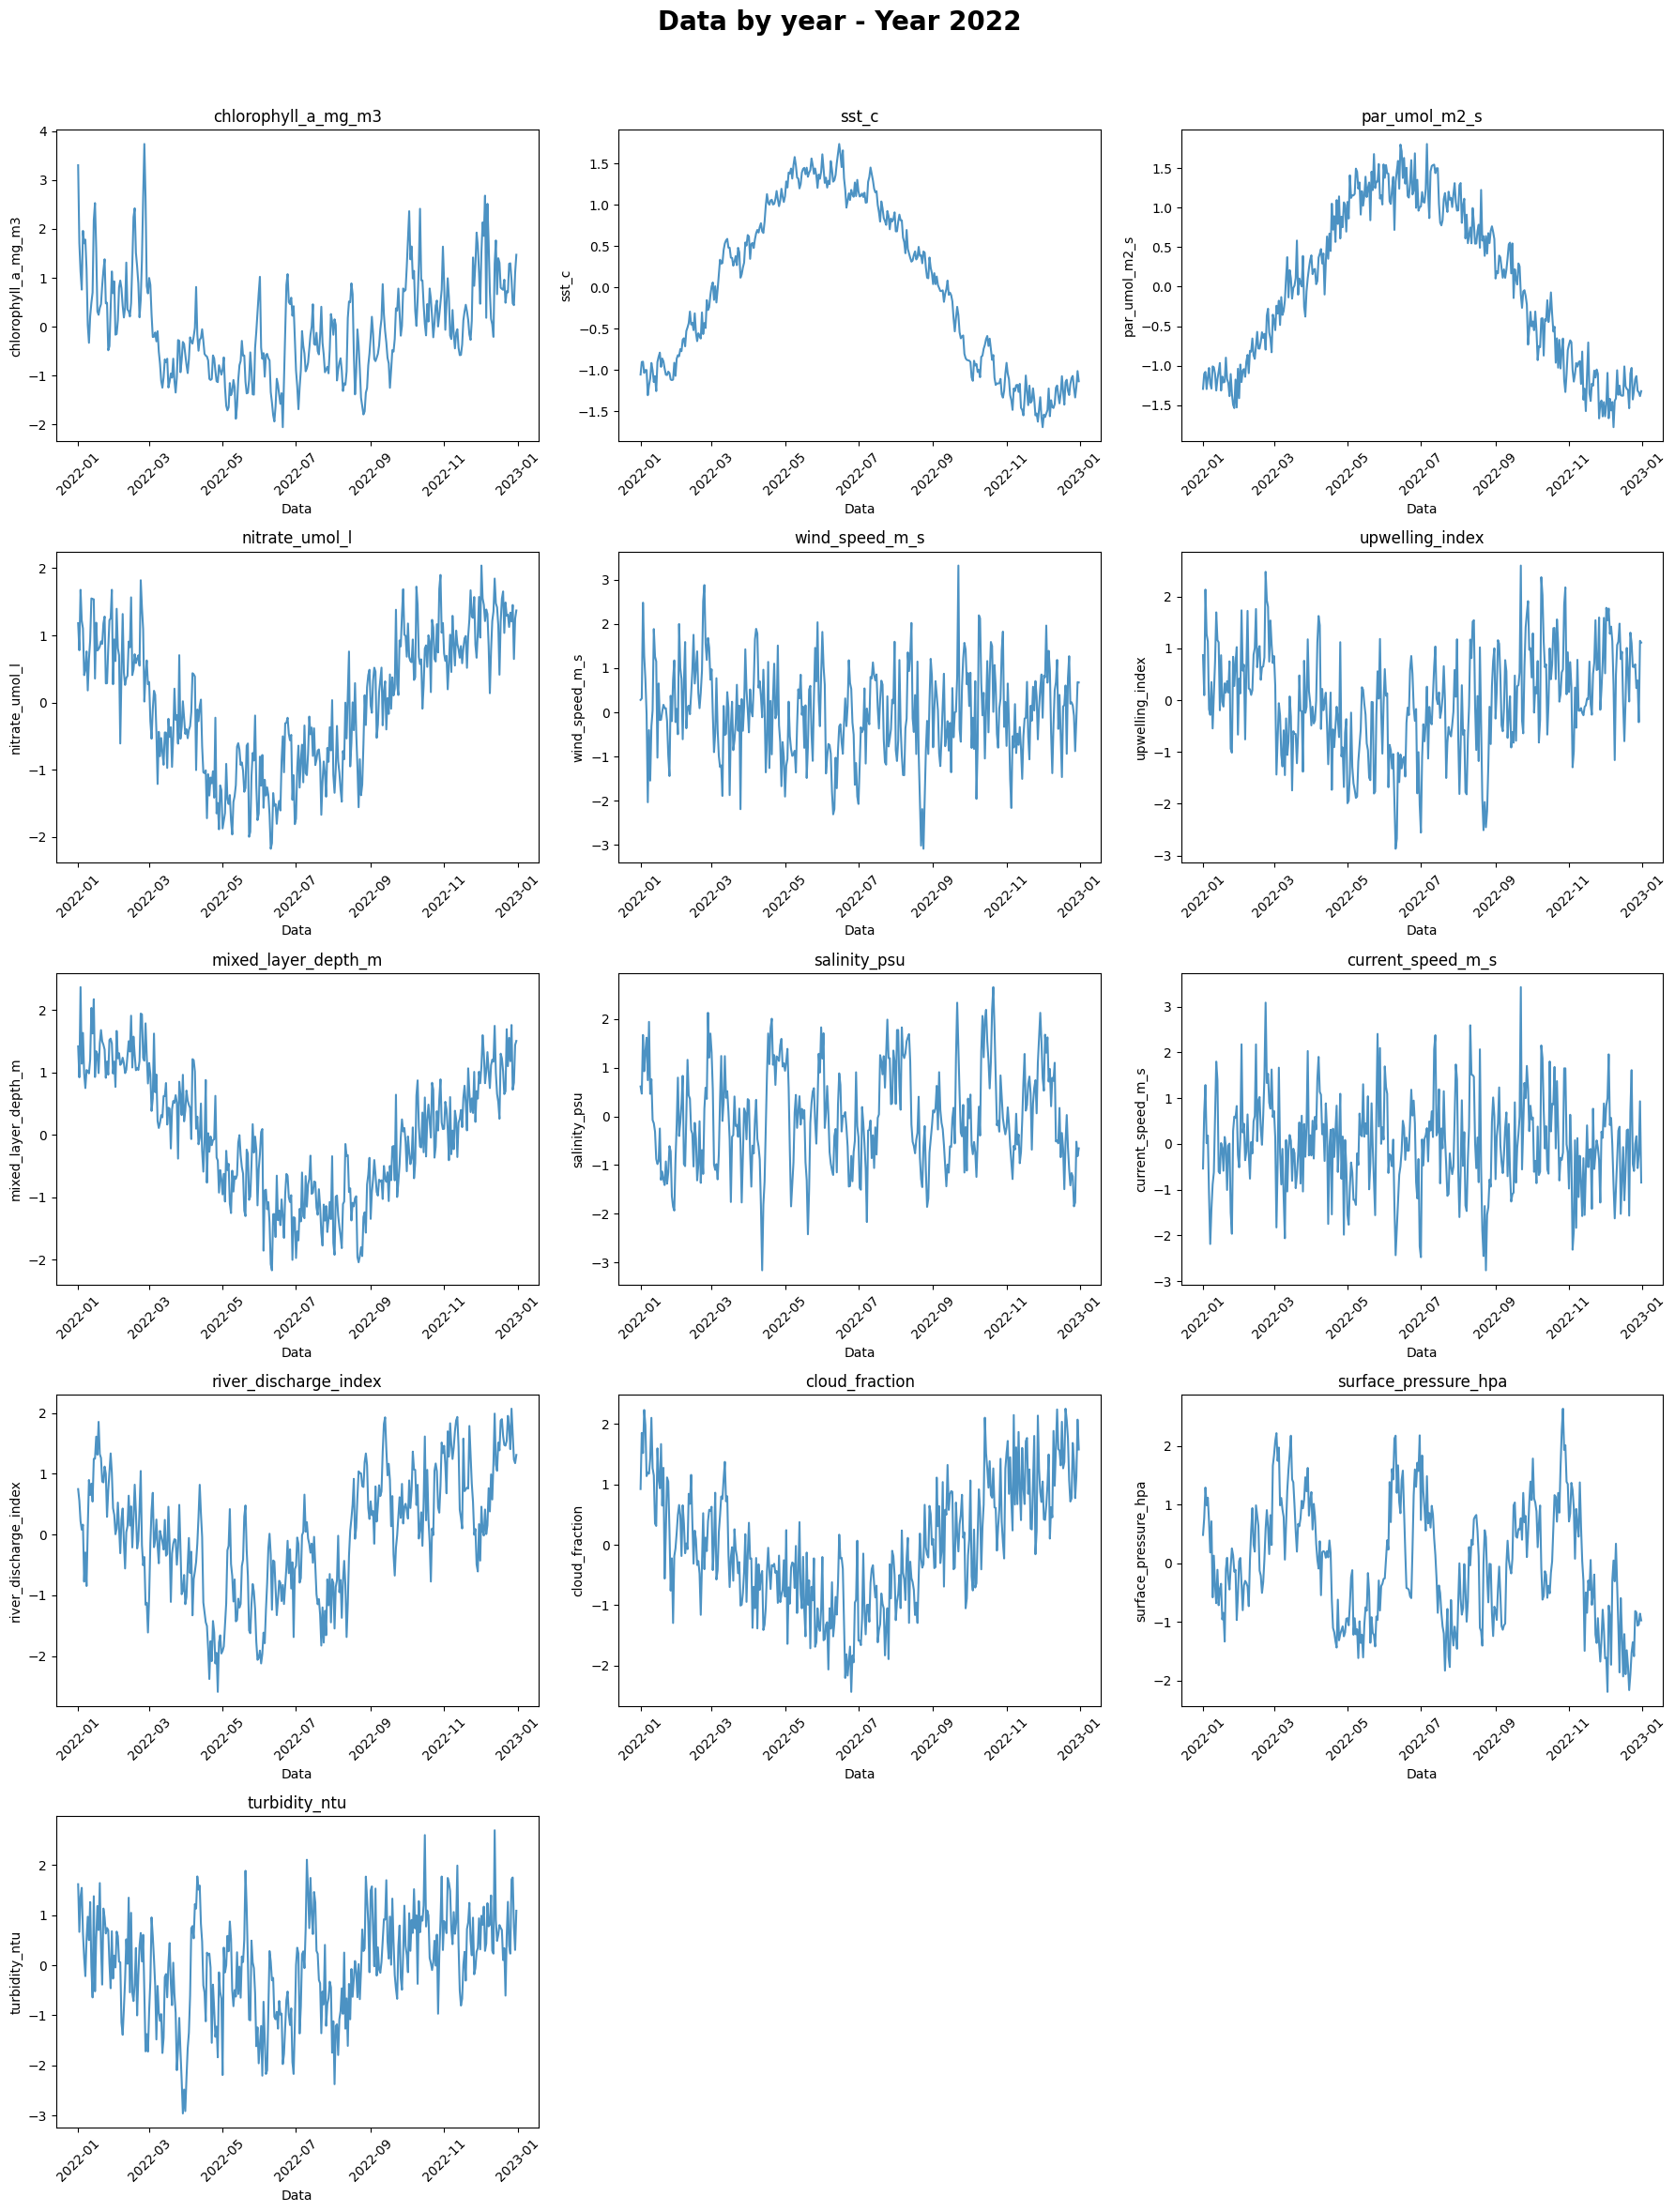

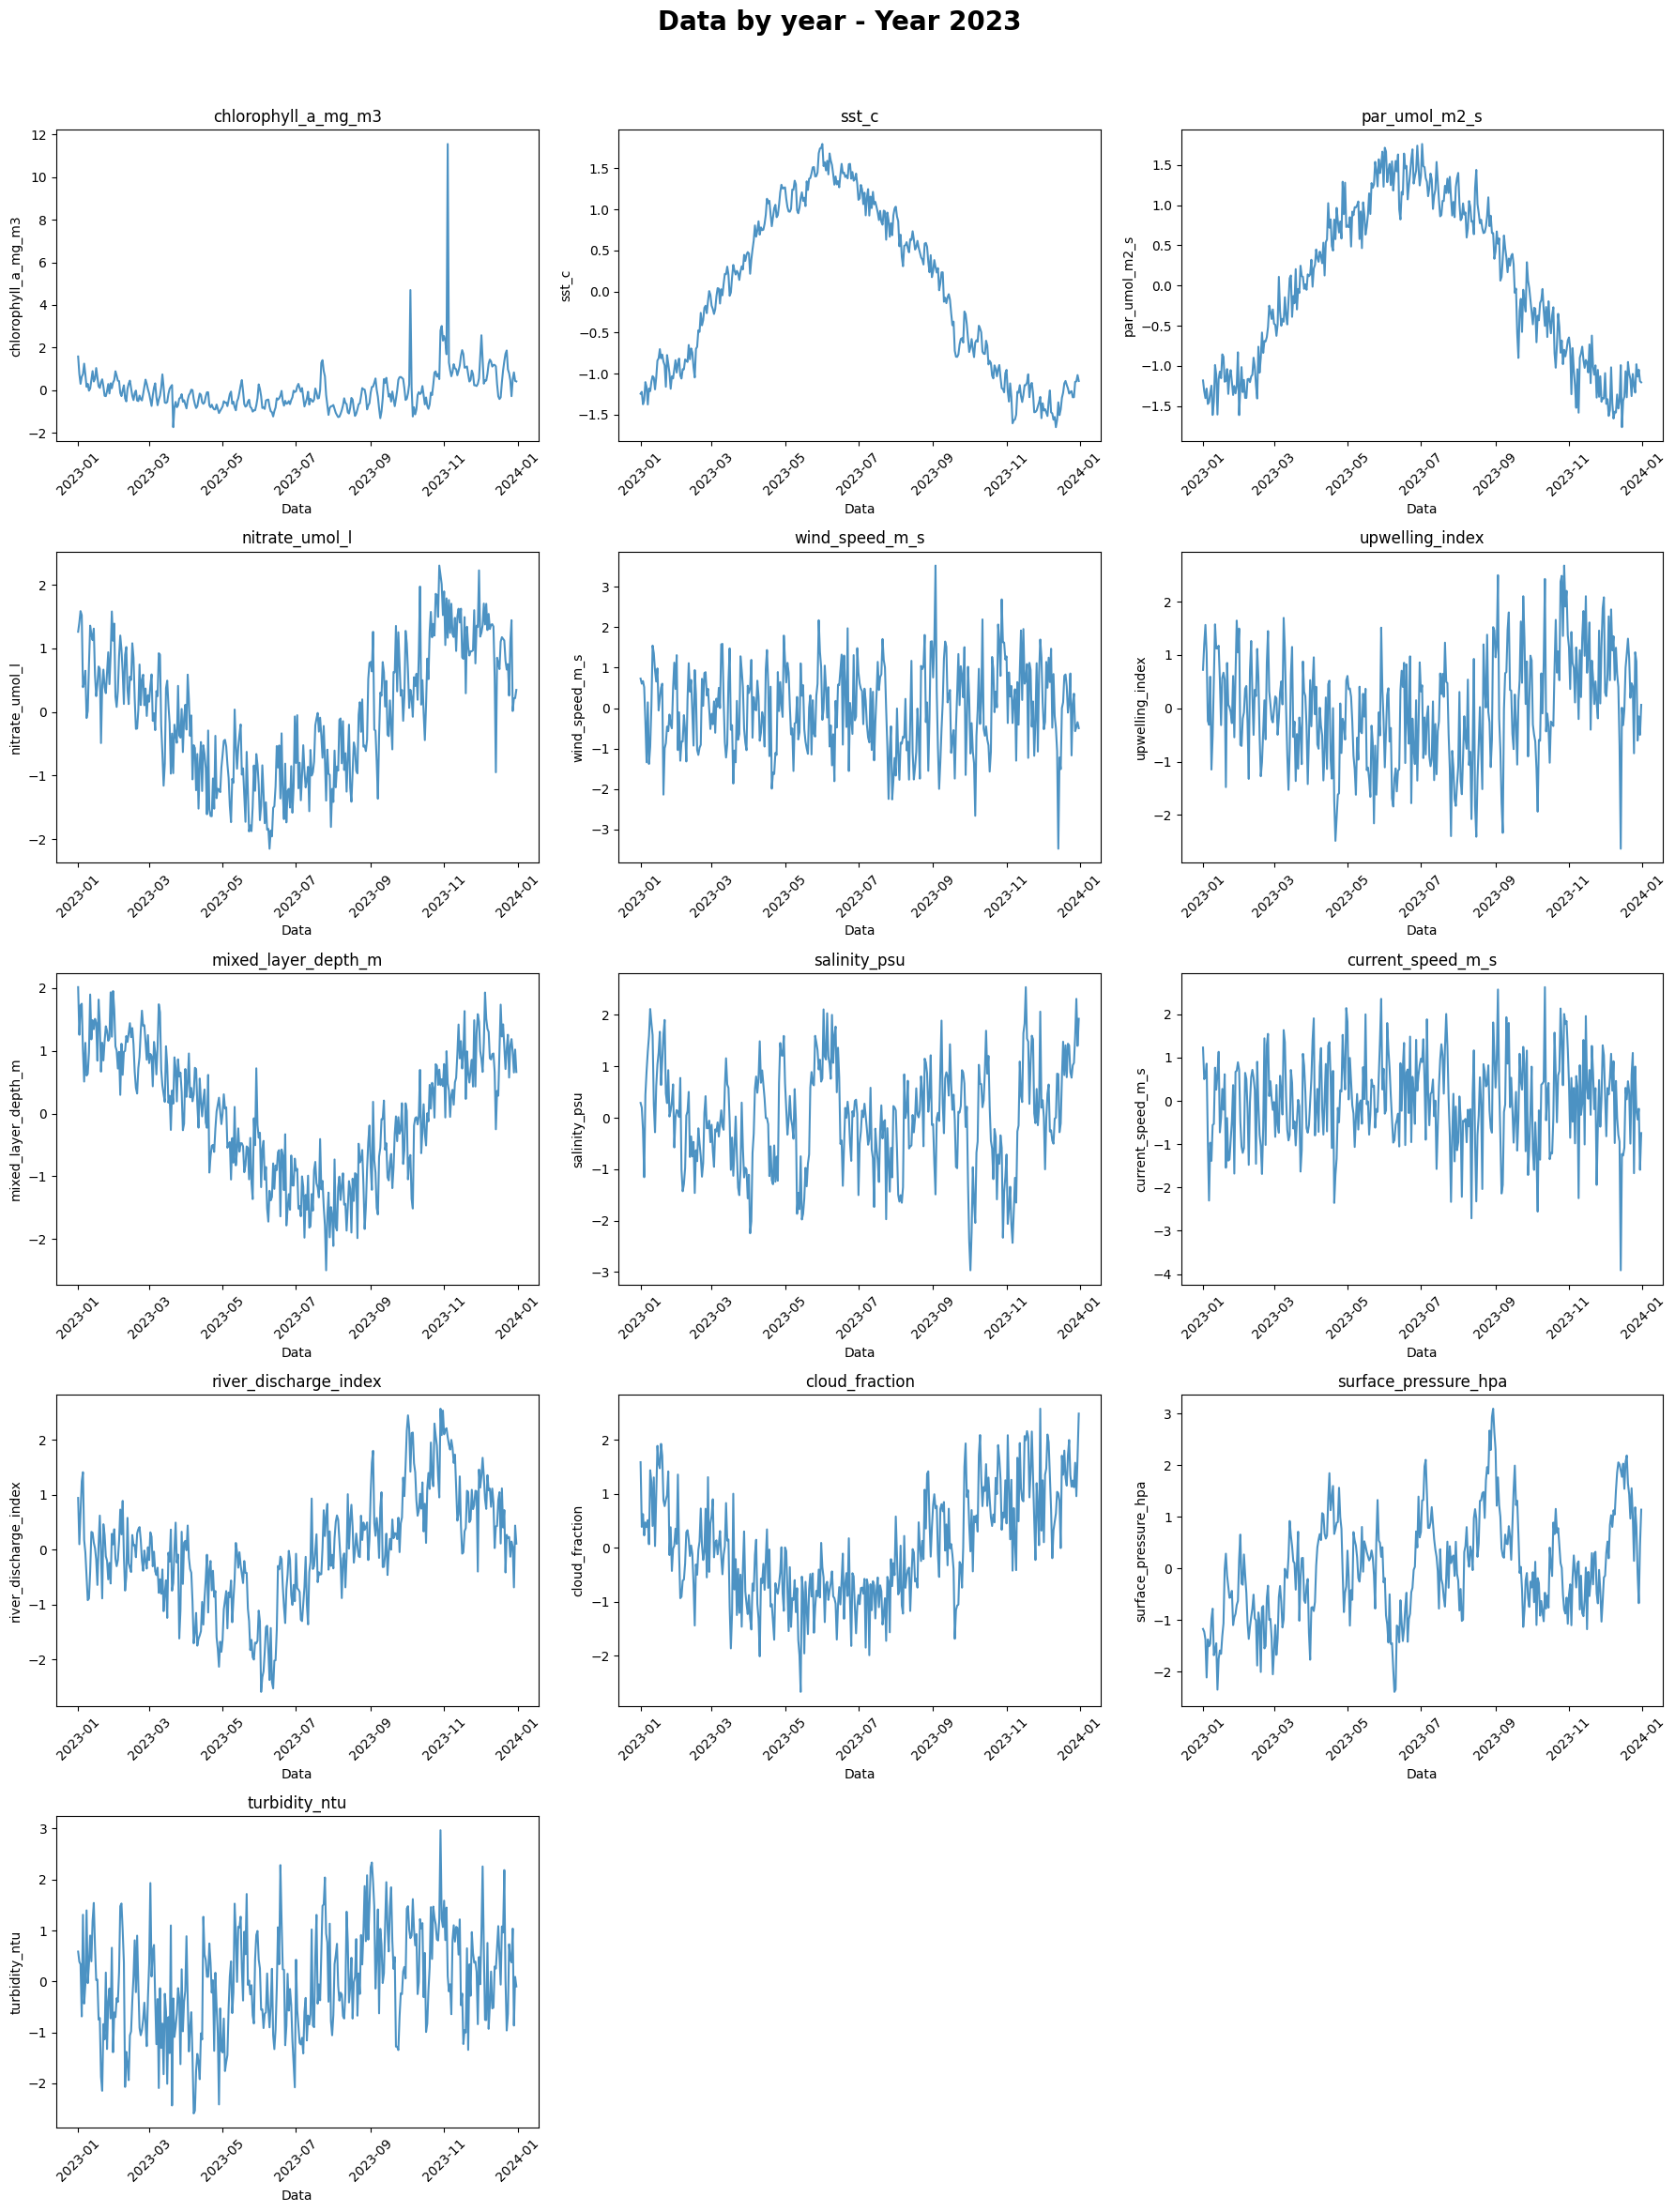

In [6]:
df_raw = pd.read_excel("../../data/chlorophyll_student_2015_2023.xlsx", sheet_name="daily_data")
df_raw["date"] = pd.to_datetime(df_raw["date"])
df_raw = df_raw.sort_values("date").reset_index(drop=True)

exogenous_cols = [col for col in df_raw.columns if col not in ["date"]]

single_year = df_raw["date"].dt.year.unique()



for year in single_year:
    
    df_year = df_raw[df_raw["date"].dt.year == year]
    
    scaler = StandardScaler()

    df_year[exogenous_cols] = scaler.fit_transform(df_year[exogenous_cols])
    
    plt.figure(figsize=(18, 24))
    
    plt.suptitle(f"Data by year - Year {year}", fontsize=20, fontweight='bold', y=0.98)
    
    for j, feature in enumerate(exogenous_cols, 1):
        plt.subplot(5, 3, j)

        plt.plot(df_year["date"], df_year[feature], alpha=0.8, linewidth=1.5)
        
        plt.title(feature)
        plt.xlabel("Data")
        plt.ylabel(feature)
        

        plt.xticks(rotation=45)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    
    plt.show()

### 3.1 Types of Preprocessing used
During development, we evaluated different combinations of preprocessing steps, tracking flags like `use_log,use_mul,use_sum,use_clip` in our `validation_results.csv` tracking file[cite: 3]. To rigorously prove which data cleaning steps actually improve generalization, we will test all 8 possible combinations of our three primary transformations:

1. **Target Skewness (`use_log`):** Applying `log1p` to Chlorophyll-a.
2. **Outlier Smoothing (`use_smooth`):** Applying a 3-day rolling average to extreme spikes (z-score out of bounds) in both the target and the lagged chlorophyll features.
3. **Hard Clipping (`use_clip`):** Restricting all exogenous features to a `[-3, 3]` standard deviation range.

We iterate through every combination using `itertools.product`. To ensure a fair comparison, all models are evaluated against the exact same **raw, unsmoothed, un-transformed Test set**.

In [ ]:
# Create a fresh, unmodified baseline for the ablation study
X_ablation = df_baseline.drop(columns=[DATE, TARGET])
Y_ablation = df_baseline[TARGET]

# 3-Way Split Indices
lower_sep = -2*365
higher_sep = -365

# We only need Train and Val for the ablation study
X_ablation_train = X_ablation.iloc[:lower_sep].copy()
X_ablation_val = X_ablation.iloc[lower_sep:higher_sep].copy()

Y_ablation_train = Y_ablation.iloc[:lower_sep].copy()
Y_ablation_val = Y_ablation.iloc[lower_sep:higher_sep].copy()


Y_ablation_train_raw = Y_ablation_train.copy()
Y_ablation_val_raw = Y_ablation_val.copy()

# Keep the original validation target for a consistent evaluation.
Y_val_ground_truth = Y_ablation_val_raw.copy()

val_y_zscores = zscore(Y_val_ground_truth)
val_outliers_y = (val_y_zscores < -3) | (val_y_zscores > 3)

Y_val_ground_truth.loc[val_outliers_y] = (
    Y_val_ground_truth
    .rolling(window=3, min_periods=1)
    .mean()
    .shift(1)[val_outliers_y]
)

# Fill any NaNs created by the rolling shift.
Y_val_ground_truth = Y_val_ground_truth.ffill().bfill().values

results = []

alpha_lasso_defined = np.logspace(-4, -2, 20)

for use_log, use_smooth, use_clip in itertools.product(
    [True, False], repeat=3
):
    # 1. Fresh copies for every configuration
    X_tr = X_ablation_train.copy()
    X_val = X_ablation_val.copy()
    Y_tr = Y_ablation_train_raw.copy()

    # 2. Log-transform target and historical chlorophyll features
    if use_log:
        Y_tr = np.log1p(Y_tr)

        chlorophyll_cols = [
            col for col in X_tr.columns
            if col.startswith("chlorophyll_a_mg_m3__lag_")
        ]

        X_tr[chlorophyll_cols] = np.log1p(X_tr[chlorophyll_cols])
        X_val[chlorophyll_cols] = np.log1p(X_val[chlorophyll_cols])

    # 3. Scale features independently for this configuration
    scaler = StandardScaler()

    X_tr_scaled = pd.DataFrame(
        scaler.fit_transform(X_tr),
        columns=X_tr.columns,
        index=X_tr.index
    )

    X_val_scaled = pd.DataFrame(
        scaler.transform(X_val),
        columns=X_val.columns,
        index=X_val.index
    )

    # 4. Optional smoothing
    if use_smooth:
        for col in X_tr_scaled.columns:
            if col.startswith("chlorophyll_a_mg_m3__lag_"):
                for X_part in (X_tr_scaled, X_val_scaled):
                    outliers = X_part[col].abs() > 3
                    replacement = (
                        X_part[col]
                        .rolling(window=3, min_periods=1)
                        .mean()
                        .shift(1)
                    )
                    X_part.loc[outliers, col] = replacement[outliers]
                    X_part[col] = X_part[col].fillna(
                        X_part[col].clip(-3, 3)
                    )
        X_val_scaled = X_val_scaled.ffill()
        X_tr_scaled = X_tr_scaled.ffill()
        # Smooth target outliers in the current target scale
        zscores = zscore(Y_tr)
        outliers = (zscores < -3) | (zscores > 3)
        replacement = Y_tr.rolling(
            window=3, min_periods=1
        ).mean().shift(1)

        Y_tr.loc[outliers] = replacement[outliers]
        Y_tr = Y_tr.ffill()

    # 5. Optional clipping
    if use_clip:
        X_tr_scaled = X_tr_scaled.clip(-3, 3)
        X_val_scaled = X_val_scaled.clip(-3, 3)

    # 6. Tune alpha for this configuration
    best_r2 = -float("inf")
    best_alpha = None
    best_mae = None

    for alpha in alpha_lasso_defined:
        model = linear_model.Lasso(
            alpha=alpha, max_iter=150000
        )
        model.fit(X_tr_scaled, Y_tr)

        preds = model.predict(X_val_scaled)

        if use_log:
            preds = np.expm1(preds)

        score = r2_score(Y_val_ground_truth, preds)
        mae = mean_absolute_error(Y_val_ground_truth, preds)

        if np.isfinite(score) and score > best_r2:
            best_r2 = score
            best_alpha = alpha
            best_mae = mae

    results.append({
        "Use Log1p": use_log,
        "Use Smoothing": use_smooth,
        "Use Clipping": use_clip,
        "Best Alpha": best_alpha,
        "Val R^2": best_r2 if best_alpha is not None else np.nan,
        "Val MAE": best_mae if best_alpha is not None else np.nan
    })

df_ablation_results = (
    pd.DataFrame(results)
    .sort_values(by="Val R^2", ascending=False)
    .reset_index(drop=True)
)

display(df_ablation_results)

,Use Log1p,Use Smoothing,Use Clipping,Best Alpha,Val R^2,Val MAE
0,True,True,False,0.000207,0.838625,0.158635
1,True,True,True,0.000207,0.838573,0.158516
2,False,True,True,0.000428,0.836194,0.162195
3,False,True,False,0.000428,0.836158,0.162362
4,True,False,False,0.007848,0.832114,0.163275
5,True,False,True,0.007848,0.831214,0.163477
6,False,False,True,0.003793,0.825078,0.168823
7,False,False,False,0.010000,0.823034,0.171415


## 4. Discarded Experiments: Interactions and Over-Engineering

During the development phase, we hypothesized that non-linear feature interactions (e.g., wind speed multiplying with sea surface temperature) might capture complex ocean dynamics better.

We generated second-order interaction terms using `itertools.combinations_with_replacement` across all lagged features. However, this exploded our dimensionality to thousands of sparse features, leading to massive overfitting and degrading the validation $R^2$ score. We also tested native `ElasticNet` implementations, but found a sequential Lasso-to-Ridge pipeline much more interpretable. 

*The code below is preserved for documentation but kept commented out.*

In [ ]:
# [DEPRECATED] Second-order interaction features
"""
raw_columns_names = [f"{col}__lag_0" for col in df_raw.drop(columns=["date", "chlorophyll_a_mg_m3"]).columns]
raw_columns_names.append("chlorophyll_a_mg_m3__lag_1")

new_columns = {}
for name, name2 in itertools.combinations_with_replacement(raw_columns_names, 2):
    new_columns[f"row_mul_{name}_{name2}"] = X_train_scaled[f"{name}"] * X_train_scaled[f"{name2}"]

df_new_features = pd.DataFrame(new_columns)
X_experimental = pd.concat([X_train_scaled, df_new_features], axis=1)

# Training a model on X_experimental resulted in severe overfitting.
"""
print("Interaction term generation skipped to maintain generalized performance.")

Interaction term generation skipped to maintain generalized performance.


## 5. Final Architecture: Lasso Selection + Ridge Regression

Our final modeling strategy leverages the strengths of two different regularization techniques:

1.  **Lasso ($L_1$ Penalty):** Used strictly as a feature selector. We run a log-space grid search to find the optimal alpha. Lasso aggressively pushes the coefficients of unhelpful features to exactly $0.0$.
2.  **Masking:** We extract the boolean mask of features that survived the Lasso penalty.
3.  **Ridge ($L_2$ Penalty):** We train a Ridge regression model exclusively on the surviving features. This mitigates the multicollinearity among the remaining highly-correlated environmental lags without arbitrarily dropping them.

Lasso selection retained 128 out of 196 features.
Final Validation R^2 (Ridge after Lasso): -0.9045
Final Validation MAE: 4.6937 mg/m3


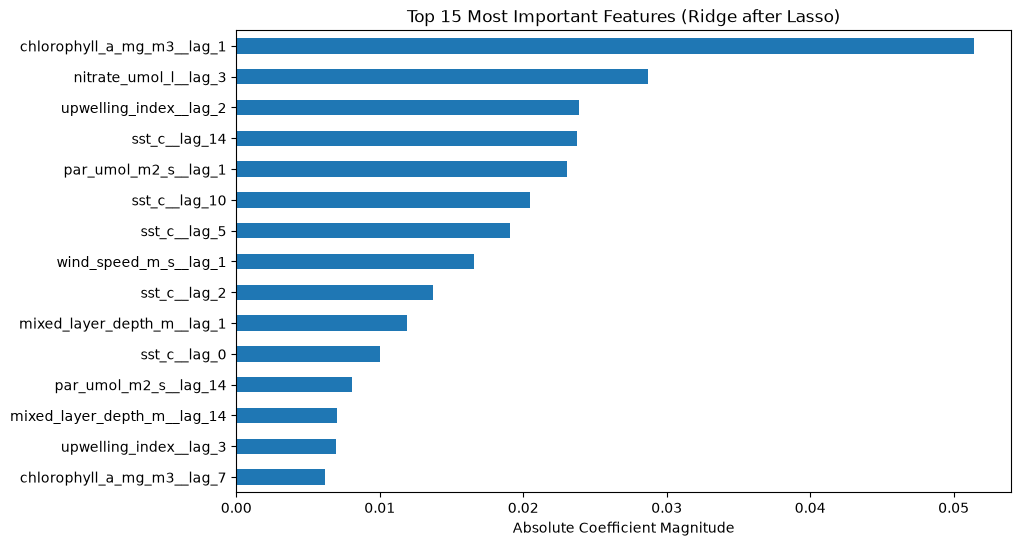

In [ ]:
# 1. Lasso for Feature Selection
alpha_lasso_defined = np.logspace(-4, -2, 20)
best_r2_lasso = -float('inf')  
best_alpha_lasso = None

# Transform validation target back to original scale for true metric calculation
Y_val_true = np.expm1(Y_val)

for alpha in alpha_lasso_defined:
    clf_lasso = linear_model.Lasso(alpha=alpha, max_iter=150000)
    clf_lasso.fit(X_train_scaled, Y_train)
    
    predicts_lasso = np.expm1(clf_lasso.predict(X_val_scaled))
    r2_lasso = r2_score(Y_val_true, predicts_lasso)

    if r2_lasso > best_r2_lasso:
        best_r2_lasso = r2_lasso
        best_alpha_lasso = alpha
        coefficients_lasso = pd.Series(clf_lasso.coef_, index=X_train_scaled.columns)

# 2. Extract Kept Features
kept_features_lasso = coefficients_lasso != 0.0
X_train_cut = X_train_scaled.loc[:, kept_features_lasso]
X_val_cut = X_val_scaled.loc[:, kept_features_lasso]

print(f"Lasso selection retained {kept_features_lasso.sum()} out of {len(kept_features_lasso)} features.")

# 3. Ridge on Selected Features
alpha_ridge_defined = np.linspace(1e-16, 1e-15, 20)
best_r2_ridge_lasso = -float('inf')  
best_alpha_ridge_lasso = None

for alpha in alpha_ridge_defined:
    clf_ridge = linear_model.Ridge(alpha=alpha)
    clf_ridge.fit(X_train_cut, Y_train)

    predicts_ridge_lasso = np.expm1(clf_ridge.predict(X_val_cut))
    r2_ridge_lasso = r2_score(Y_val_true, predicts_ridge_lasso)

    if r2_ridge_lasso > best_r2_ridge_lasso:
        best_r2_ridge_lasso = r2_ridge_lasso
        best_alpha_ridge_lasso = alpha
        mae_best_ridge_lasso = mean_absolute_error(Y_val_true, predicts_ridge_lasso)
        coefficients_ridge_lasso = pd.Series(clf_ridge.coef_, index=X_train_cut.columns)

print(f"Final Validation R^2 (Ridge after Lasso): {best_r2_ridge_lasso:.4f}")
print(f"Final Validation MAE: {mae_best_ridge_lasso:.4f} mg/m3")

# Plot Top Features
importance_ridge_lasso = coefficients_ridge_lasso.abs().sort_values(ascending=False).head(15)
plt.figure(figsize=(10, 6))
importance_ridge_lasso.plot(kind='barh')
plt.title("Top 15 Most Important Features (Ridge after Lasso)")
plt.gca().invert_yaxis()
plt.xlabel("Absolute Coefficient Magnitude")
plt.show()